# EXPERIMENT: EXP-DENSENET121-SCRATCH-5SEEDS-008 — TRAINING / VALIDATION

## DenseNet121 Scratch — 5-seed final protocol after A_4

This run freezes the recipe selected in A_4 and repeats it for seeds
`[42, 123, 2026, 3407, 7777]`:

- dataset archive: `CashewData_Split (7).zip`;
- Train 4,825 / Validation 1,395 / locked Test 687;
- scratch DenseNet121, BatchNorm momentum 0.90 in backbone and head;
- peak LR 3e-4, three-epoch linear warmup, cosine decay to 1e-6;
- up to 30 epochs; EarlyStopping monitors Validation macro-F1 from epoch 19 with patience 8;
- no ReduceLROnPlateau;
- checkpoint selection by Validation macro-F1, then lower Validation loss, then earlier epoch.

`RUN_FINAL_TEST=False` during the complete five-seed run. Test and the external
holdout are not used for training, checkpoint selection, seed ranking, or recipe
selection. `Run All` trains all five seeds, builds the Validation-selected
deployment package, and creates the result archives while Test metrics remain locked.


In [1]:
import sys
print("Python:", sys.executable)

!nvidia-smi

Python: /usr/bin/python3
Mon Oct 12 15:16:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   49C    P0             29W /   72W |    8404MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------

In [2]:

# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import sys
import io
import gc
import json
import time
import random
import shutil
import platform
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)

from IPython.display import display
import ipywidgets as widgets

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)

print("Imports completed.")


Imports completed.


In [3]:

# ============================================================
# 02. ENVIRONMENT INFORMATION
# ============================================================

print(f"Date              : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python            : {sys.version.split()[0]}")
print(f"TensorFlow        : {tf.__version__}")
print(f"Keras             : {keras.__version__ if hasattr(keras, '__version__') else 'tf.keras'}")
RUNTIME = ("Windows" if os.name == "nt" else "Kaggle" if Path("/kaggle/working").is_dir() else "Colab" if Path("/content").is_dir() else platform.system())
print(f"Runtime           : {RUNTIME}")
print(f"OS                : {platform.platform()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU Count         : {len(gpus)}")
if RUNTIME == "Colab" and not gpus:
    raise RuntimeError("Colab has no GPU. Select a GPU runtime and rerun from the first cell.")

for i, gpu in enumerate(gpus):
    print(f"GPU {i}             : {gpu}")

if len(gpus) >= 2:
    strategy = tf.distribute.MirroredStrategy()
elif len(gpus) == 1:
    strategy = tf.distribute.OneDeviceStrategy(device="/GPU:0")
else:
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")

print(f"Strategy          : {strategy.__class__.__name__}")
print(f"Replicas          : {strategy.num_replicas_in_sync}")


Date              : 2026-10-12 15:17:03
Python            : 3.13.15
TensorFlow        : 2.21.0
Keras             : 3.13.2
Runtime           : Colab
OS                : Linux-6.6.122+-x86_64-with-glibc2.39
GPU Count         : 1
GPU 0             : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Strategy          : OneDeviceStrategy
Replicas          : 1


In [4]:

# ============================================================
# 03. CONFIGURATION
# ============================================================

NOTEBOOK_VERSION = "008"
EXPERIMENT_ID = "EXP-DENSENET121-SCRATCH-5SEEDS-008"
DATASET_VERSION = "Cashew_dataV07_clean_val"
DATASET_ARCHIVE_NAME = "CashewData_Split (7).zip"
DATASET_ARCHIVE_FILE_ID = None  # Mounted Drive path is authoritative for archive (7).


DRIVE_TARGET_URL = (
    "https://drive.google.com/drive/folders/"
    "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing"
)
DRIVE_TARGET_FOLDER_ID = "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti"

EXPECTED_CLASSES = [
    "anthracnose",
    "healthy",
    "leaf_miner",
    "not_cashew_leaf",
    "red_rust",
]

EXPECTED_COUNTS = {
    "anthracnose": {
        "train": 948,
        "val": 299,
        "test": 122,
        "total": 1369,
    },

    "healthy": {
        "train": 806,
        "val": 213,
        "test": 118,
        "total": 1137,
    },

    "leaf_miner": {
        "train": 893,
        "val": 246,
        "test": 132,
        "total": 1271,
    },

    "not_cashew_leaf": {
        "train": 1101,
        "val": 314,
        "test": 157,
        "total": 1572,
    },

    "red_rust": {
        "train": 1077,
        "val": 323,
        "test": 158,
        "total": 1558,
    },
}

EXPECTED_TOTALS = {
    "train": 4825,
    "val": 1395,
    "test": 687,
    "total": 6907,
}

STRICT_DATASET_CHECK = True


# These conflicting-label copies were removed before archive (7) was created.
REQUIRED_ABSENT_IMAGES = [
    "val/leaf_miner/leaf_miner_1056.jpg",
    "val/leaf_miner/leaf_miner_1091.jpg",
]

# ------------------------------------------------------------
# 5-SEED PROTOCOL
# ------------------------------------------------------------

SEEDS = [42, 123, 2026, 3407, 7777]
DEMO_SEED = None  # set later from Validation-only deployment selection

# ------------------------------------------------------------
# TRAINING
# ------------------------------------------------------------

IMG_SIZE = 224
BATCH_SIZE = 32
MAX_EPOCHS = 30
INITIAL_LR = 3e-4  # Peak LR; optimizer starts at WARMUP_START_LR.
WARMUP_EPOCHS = 3
WARMUP_START_LR = 1e-5

MODEL_NAME = "DenseNet121"
TRAINING_MODE = "Scratch"
PRETRAINED_WEIGHTS = None

HEAD_UNITS = 512
HEAD_DROPOUT = 0.40

MIN_LR = 1e-6
CHECKPOINT_SELECTION = "val_macro_f1_desc_val_loss_asc_epoch_asc"
EARLY_STOPPING_START_EPOCH = 19  # One-based; allow LR to anneal before monitoring.
EARLY_STOPPING_PATIENCE = 8

# ------------------------------------------------------------
# LOCKED TEST
# ------------------------------------------------------------

RUN_FINAL_TEST = False  # Keep locked for the complete EXP-008 training/Validation run.

# External images are never used by model.fit or checkpoint/seed selection.
RUN_REAL_HOLDOUT = False  # External holdout remains disabled for this training experiment.
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout.zip"
REAL_HOLDOUT_ARCHIVE_SHA256 = "BDDCB61CA9AF6111E0B26DB7876D0A3309C587AEAFFAEF49B7A9D2D162309165"
REAL_HOLDOUT_EXPECTED_COUNTS = {"anthracnose": 13, "healthy": 5, "leaf_miner": 24, "red_rust": 7}
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None  # Optional mounted/local ZIP path.
RUN_TRAINING = True  # Fresh five-seed EXP-008 run.

if RUN_REAL_HOLDOUT:
    raise RuntimeError("Real Holdout is disabled for this EXP-008 training experiment.")

# ------------------------------------------------------------
# STORAGE
# ------------------------------------------------------------

# Chỉ lưu best weights để giảm mạnh dung lượng.
# Không lưu last.keras.
SAVE_BEST_WEIGHTS_ONLY = True

if RUNTIME == "Windows":
    PROJECT_ROOT = Path(r"D:\Study\KhoaLuanTotNghiep\Resource")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Kaggle":
    PROJECT_ROOT = Path("/kaggle/working")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content")
    DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/Cashew_Leaf_model_result")
    DRIVE_DATASET_DIR = DRIVE_PROJECT_DIR / "Dataset"
    DRIVE_DATASET_ARCHIVE = DRIVE_DATASET_DIR / DATASET_ARCHIVE_NAME
    if not DRIVE_PROJECT_DIR.is_dir():
        raise FileNotFoundError(
            f"Results folder not found: {DRIVE_PROJECT_DIR}. Add a shortcut to My Drive or change DRIVE_PROJECT_DIR."
        )
    RESULTS_ROOT = DRIVE_PROJECT_DIR / "training_results" / "current_dataset"
else:
    raise RuntimeError(f"Unsupported runtime: {RUNTIME}. Use Windows, Kaggle or Colab.")
OUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
AGGREGATE_DIR = OUT_DIR / "aggregate"
PANEL_DIR = OUT_DIR / "figures" / "panels"
MODEL_PACKAGE_DIR = OUT_DIR / "model_package"
CODE_PACKAGE_DIR = OUT_DIR / "code"
ENV_DIR = OUT_DIR / "environment"

existing_seed_files = [
    path for seed in SEEDS
    for path in (OUT_DIR / f"seed_{seed}").rglob("*")
    if path.is_file()
] if OUT_DIR.exists() else []
if RUN_TRAINING and existing_seed_files:
    raise FileExistsError(
        f"Training artifacts already exist in {OUT_DIR}; first file: {existing_seed_files[0]}. "
        "Use a new experiment ID or RUN_TRAINING=False to preserve them."
    )
if not RUN_TRAINING and not (OUT_DIR / "experiment_config.json").exists():
    raise FileNotFoundError("Evaluation-only mode requires saved training results.")

for folder in [
    OUT_DIR,
    AGGREGATE_DIR,
    PANEL_DIR,
    MODEL_PACKAGE_DIR,
    CODE_PACKAGE_DIR,
    ENV_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

if not RUN_TRAINING:
    resume_required = [
        OUT_DIR / "experiment_config.json",
        AGGREGATE_DIR / "training_summary_5seeds.csv",
        AGGREGATE_DIR / "validation_results_5seeds.csv",
        *[
            OUT_DIR / f"seed_{seed}" / "checkpoints" /
            f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5"
            for seed in SEEDS
        ],
    ]
    missing_resume_files = [path for path in resume_required if not path.is_file()]
    if missing_resume_files:
        raise FileNotFoundError(
            "EXP-008 cannot resume Final Test; missing:\n" +
            "\n".join(str(path) for path in missing_resume_files)
        )
    print("Resume check passed: five EXP-008 checkpoints and Validation summaries found.")

print("Experiment ID    :", EXPERIMENT_ID)
print("Dataset version  :", DATASET_VERSION)
print("Seeds            :", SEEDS)
print("Image size       :", IMG_SIZE)
print("Batch size       :", BATCH_SIZE)
print("Max epochs       :", MAX_EPOCHS)
print("Peak LR          :", INITIAL_LR)
print("Warmup epochs     :", WARMUP_EPOCHS)
print("Minimum LR       :", MIN_LR)
print("RUN_FINAL_TEST   :", RUN_FINAL_TEST)
print("RUN_REAL_HOLDOUT :", RUN_REAL_HOLDOUT)
print("RUN_TRAINING     :", RUN_TRAINING)

print("Drive target     :", DRIVE_TARGET_URL)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment ID    : EXP-DENSENET121-SCRATCH-5SEEDS-008
Dataset version  : Cashew_dataV07_clean_val
Seeds            : [42, 123, 2026, 3407, 7777]
Image size       : 224
Batch size       : 32
Max epochs       : 30
Peak LR          : 0.0003
Warmup epochs     : 3
Minimum LR       : 1e-06
RUN_FINAL_TEST   : False
RUN_REAL_HOLDOUT : False
RUN_TRAINING     : True
Drive target     : https://drive.google.com/drive/folders/1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing


In [5]:

# ============================================================
# 04. REPRODUCIBILITY
# ============================================================

def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Đồng bộ Python / NumPy / TensorFlow theo Keras.
    try:
        keras.utils.set_random_seed(seed)
    except Exception:
        pass

    print(f"Global seed set to: {seed}")


try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic operations: ENABLED")
except Exception as e:
    print("Deterministic operations: unavailable")
    print("Reason:", e)


Deterministic operations: ENABLED


In [6]:

# ============================================================
# 05. LOAD FIXED DATASET
# ============================================================

if RUNTIME == "Windows":
    DATASET_PATH = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset\CashewData_Split")
elif RUNTIME == "Kaggle":
    dataset_candidates = sorted(
        path for path in Path("/kaggle/input").rglob("CashewData_Split")
        if path.is_dir() and all((path / split).is_dir() for split in ("train", "val", "test"))
    )
    if len(dataset_candidates) != 1:
        raise RuntimeError(f"Expected one CashewData_Split under /kaggle/input; found: {dataset_candidates}")
    DATASET_PATH = dataset_candidates[0]
else:  # Colab
    DATASET_PATH = Path("/content/CashewData_Split")
    if DRIVE_DATASET_ARCHIVE.is_file() and DATASET_PATH.exists():
        print("Refreshing local dataset from:", DRIVE_DATASET_ARCHIVE)
        shutil.rmtree(DATASET_PATH)
    if not all((DATASET_PATH / split).is_dir() for split in ("train", "val", "test")):
        archive_path = DRIVE_DATASET_ARCHIVE
        drive_dataset = DRIVE_DATASET_DIR / "CashewData_Split"
        if archive_path.is_file():
            extraction_root = Path("/content").resolve()
            with zipfile.ZipFile(archive_path) as dataset_archive:
                for member in dataset_archive.infolist():
                    target = (extraction_root / member.filename).resolve()
                    if target != extraction_root and extraction_root not in target.parents:
                        raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
                print("Extracting dataset from:", archive_path)
                dataset_archive.extractall(extraction_root)
        elif all((drive_dataset / split).is_dir() for split in ("train", "val", "test")):
            if DATASET_PATH.exists():
                raise RuntimeError(f"Incomplete local dataset at {DATASET_PATH}; use a fresh Colab runtime.")
            shutil.copytree(drive_dataset, DATASET_PATH)
        else:
            raise FileNotFoundError(
                f"Dataset not found: expected {archive_path} or {drive_dataset}. Check DRIVE_DATASET_DIR."
            )

required_splits = [DATASET_PATH / name for name in ("train", "val", "test")]
missing_splits = [str(path) for path in required_splits if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(
        "Dataset path is missing required split folders: " + str(missing_splits)
    )

TRAIN_DIR = DATASET_PATH / "train"
VAL_DIR = DATASET_PATH / "val"
TEST_DIR = DATASET_PATH / "test"


unexpected_removed_files = [
    DATASET_PATH / Path(relative_path)
    for relative_path in REQUIRED_ABSENT_IMAGES
    if (DATASET_PATH / Path(relative_path)).is_file()
]
if unexpected_removed_files:
    raise ValueError(
        "Archive (7) still contains the two removed Validation copies:\n" +
        "\n".join(str(path) for path in unexpected_removed_files)
    )

print("\nSelected dataset:")
print("DATASET_PATH :", DATASET_PATH)
print("TRAIN_DIR    :", TRAIN_DIR)
print("VAL_DIR      :", VAL_DIR)
print("TEST_DIR     :", TEST_DIR)


Refreshing local dataset from: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (7).zip
Extracting dataset from: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (7).zip

Selected dataset:
DATASET_PATH : /content/CashewData_Split
TRAIN_DIR    : /content/CashewData_Split/train
VAL_DIR      : /content/CashewData_Split/val
TEST_DIR     : /content/CashewData_Split/test



# Dataset Audit

Notebook kiểm tra lại toàn bộ ảnh trước khi train.

Nếu:
- có ảnh decode lỗi;
- có file extension lạ;
- class folder sai;
- số lượng khác revision sạch trong `CashewData_Split (7).zip`;

thì notebook sẽ **dừng** khi `STRICT_DATASET_CHECK=True`.


In [7]:

# ============================================================
# 06. DATASET AUDIT + EXACT COUNTS
# ============================================================

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"
}


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def audit_split(split_name, split_dir):
    valid_rows = []
    bad_rows = []
    unknown_rows = []

    found_classes = sorted([
        p.name for p in split_dir.iterdir()
        if p.is_dir()
    ])

    if found_classes != sorted(EXPECTED_CLASSES):
        raise ValueError(
            f"Class folders của {split_name} không đúng.\n"
            f"Expected: {sorted(EXPECTED_CLASSES)}\n"
            f"Found   : {found_classes}"
        )

    for label, class_name in enumerate(EXPECTED_CLASSES):
        class_dir = split_dir / class_name

        for path in sorted(class_dir.rglob("*")):
            if not path.is_file():
                continue

            ext = path.suffix.lower()

            if ext not in VALID_EXTENSIONS:
                unknown_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "extension": ext,
                })
                continue

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    img.convert("RGB").load()

                valid_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "label": label,
                    "path": str(path),
                    "relative_path": path.relative_to(DATASET_PATH).as_posix(),
                    "sha256": sha256_file(path),
                })

            except Exception as e:
                bad_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "error": str(e),
                })

    return valid_rows, bad_rows, unknown_rows


all_valid = []
all_bad = []
all_unknown = []

for split_name, split_dir in {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR,
}.items():

    print(f"Checking {split_name}...")

    valid_rows, bad_rows, unknown_rows = audit_split(
        split_name,
        split_dir
    )

    all_valid.extend(valid_rows)
    all_bad.extend(bad_rows)
    all_unknown.extend(unknown_rows)


valid_df = pd.DataFrame(all_valid)
bad_df = pd.DataFrame(all_bad)
unknown_df = pd.DataFrame(all_unknown)

print("\n" + "=" * 70)
print("VALID IMAGES   :", len(valid_df))
print("INVALID IMAGES :", len(bad_df))
print("UNKNOWN FILES  :", len(unknown_df))
print("=" * 70)

if len(bad_df):
    display(bad_df)

if len(unknown_df):
    display(unknown_df)

bad_df.to_csv(OUT_DIR / "invalid_images.csv", index=False)
unknown_df.to_csv(OUT_DIR / "unknown_files.csv", index=False)

if len(bad_df):
    raise ValueError("Dataset còn ảnh lỗi. Hãy clean dataset trước khi train.")

if len(unknown_df):
    raise ValueError("Dataset có file extension lạ. Hãy kiểm tra trước khi train.")


stats_df = (
    valid_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(EXPECTED_CLASSES)
)

for col in ["train", "val", "test"]:
    if col not in stats_df.columns:
        stats_df[col] = 0

stats_df = stats_df[["train", "val", "test"]]
stats_df["total"] = stats_df.sum(axis=1)

display(stats_df)

actual_totals = {
    "train": int(stats_df["train"].sum()),
    "val": int(stats_df["val"].sum()),
    "test": int(stats_df["test"].sum()),
    "total": int(stats_df["total"].sum()),
}

mismatches = []

for class_name in EXPECTED_CLASSES:
    for split_name in ["train", "val", "test", "total"]:

        actual = int(stats_df.loc[class_name, split_name])
        expected = int(EXPECTED_COUNTS[class_name][split_name])

        if actual != expected:
            mismatches.append({
                "class": class_name,
                "split": split_name,
                "actual": actual,
                "expected": expected,
            })

for split_name in ["train", "val", "test", "total"]:
    if actual_totals[split_name] != EXPECTED_TOTALS[split_name]:
        mismatches.append({
            "class": "TOTAL",
            "split": split_name,
            "actual": actual_totals[split_name],
            "expected": EXPECTED_TOTALS[split_name],
        })

if mismatches:
    mismatch_df = pd.DataFrame(mismatches)
    display(mismatch_df)

    if STRICT_DATASET_CHECK:
        raise ValueError(
            "Dataset count does not match the frozen archive (7) clean-Validation revision."
        )
else:
    print("Dataset counts match the frozen archive (7) clean-Validation revision.")
    print(actual_totals)


# Save manifest để biết chính xác file nào thuộc split nào.
valid_df.to_csv(
    OUT_DIR / "dataset_manifest.csv",
    index=False
)


manifest_records = valid_df[["relative_path", "label", "sha256"]].to_dict("records")
DATASET_MANIFEST_SHA256 = hashlib.sha256(
    json.dumps(manifest_records, sort_keys=True, separators=(",", ":")).encode()
).hexdigest()
(OUT_DIR / "dataset_manifest_sha256.txt").write_text(DATASET_MANIFEST_SHA256 + "\n", encoding="utf-8")
print("Dataset manifest SHA256:", DATASET_MANIFEST_SHA256)


Checking train...
Checking val...
Checking test...

VALID IMAGES   : 6907
INVALID IMAGES : 0
UNKNOWN FILES  : 0


split,train,val,test,total
class,,,,
anthracnose,948,299,122,1369
healthy,806,213,118,1137
leaf_miner,893,246,132,1271
not_cashew_leaf,1101,314,157,1572
red_rust,1077,323,158,1558


Dataset counts match the frozen archive (7) clean-Validation revision.
{'train': 4825, 'val': 1395, 'test': 687, 'total': 6907}
Dataset manifest SHA256: b45a74e61fbfa8bdff07ea94c469449fb3bf81dd91e19318cb643b4b71214768


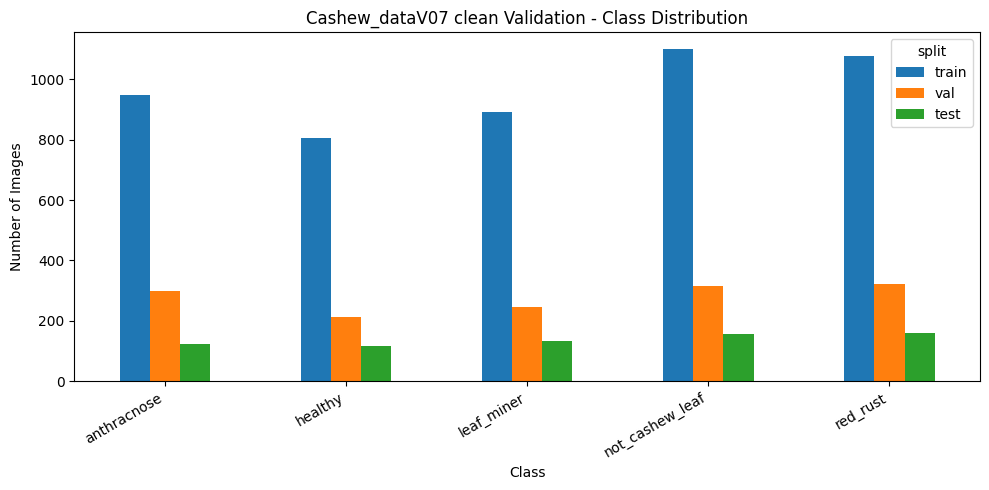

In [8]:

# ============================================================
# 07. DATASET DISTRIBUTION
# ============================================================

ax = stats_df[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Cashew_dataV07 clean Validation - Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    AGGREGATE_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [9]:

# ============================================================
# 08. FIXED FILE LISTS + TF.DATA
# ============================================================

CLASS_NAMES = EXPECTED_CLASSES
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE


def split_arrays(split_name):
    df = (
        valid_df[valid_df["split"] == split_name]
        .copy()
        .reset_index(drop=True)
    )

    return (
        df["path"].to_numpy(),
        df["label"].to_numpy(dtype=np.int32),
        df
    )


train_paths, train_labels, train_meta = split_arrays("train")
val_paths, val_labels, val_meta = split_arrays("val")
test_paths, test_labels, test_meta = split_arrays("test")


def decode_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    return tf.cast(image, tf.float32), label


def make_dataset(paths, labels, seed, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=seed,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        decode_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    ds = ds.prefetch(AUTOTUNE)

    return ds


print("Fixed split:")
print("Train :", len(train_paths))
print("Val   :", len(val_paths))
print("Test  :", len(test_paths))

print("\nClass mapping:")
for idx, class_name in enumerate(CLASS_NAMES):
    print(f"{idx}: {class_name}")


Fixed split:
Train : 4825
Val   : 1395
Test  : 687

Class mapping:
0: anthracnose
1: healthy
2: leaf_miner
3: not_cashew_leaf
4: red_rust


# Model Builder

The EXP-008 architecture is fixed before the five-seed run. DenseNet121 is
initialized from scratch. Every BatchNormalization layer in its backbone and
the classifier head uses `momentum=0.90`. The backbone is called as
`x = backbone(x)`, so Keras selects training/inference behavior normally.


In [10]:

# ============================================================
# 09. DATA AUGMENTATION + DENSENET121 MODEL BUILDER
# ============================================================

AUGMENTATION_CONFIG = {
    "horizontal_flip": True,
    "vertical_flip": False,
    "rotation_factor": 0.04,
    "zoom_factor": 0.05,
    "translation_factor": 0.03,
    "contrast_factor": 0.08,
    "brightness": False,
    "hue_shift": False,
}


def build_data_augmentation(seed):
    return keras.Sequential(
        [
            layers.RandomFlip(
                "horizontal",
                seed=seed + 1
            ),

            layers.RandomRotation(
                factor=0.04,
                seed=seed + 2
            ),

            layers.RandomZoom(
                height_factor=(-0.05, 0.05),
                width_factor=(-0.05, 0.05),
                seed=seed + 3
            ),

            layers.RandomTranslation(
                height_factor=0.03,
                width_factor=0.03,
                seed=seed + 4
            ),

            layers.RandomContrast(
                factor=0.08,
                seed=seed + 5
            ),
        ],
        name=f"data_augmentation_seed_{seed}"
    )


def build_densenet121_model(seed):

    set_global_seed(seed)

    augmentation = build_data_augmentation(seed)

    inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image"
    )

    # Augmentation chỉ hoạt động khi model ở training mode.
    x = augmentation(inputs)

    # Scratch training: normalize ảnh về [0,1].
    x = layers.Rescaling(
        1.0 / 255.0,
        name="rescale_0_1"
    )(x)

    backbone = tf.keras.applications.DenseNet121(
        include_top=False,
        weights=None,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    backbone.trainable = True

    # A_4 showed that the default 0.99 causes slow running-stat adaptation.
    # Use 0.90 for every BatchNorm layer in the scratch backbone.
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.momentum = 0.90

    # ========================================================
    # QUAN TRỌNG:
    # Không ép training=True.
    # ========================================================
    x = backbone(x)

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        HEAD_UNITS,
        activation="relu",
        name="classifier_dense"
    )(x)

    x = layers.BatchNormalization(
        momentum=0.90,
        name="classifier_bn"
    )(x)

    x = layers.Dropout(
        HEAD_DROPOUT,
        seed=seed + 6,
        name="classifier_dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="predictions"
    )(x)

    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name=f"DenseNet121_Scratch_seed_{seed}"
    )


print("Defined:")
print("- build_data_augmentation(seed)")
print("- build_densenet121_model(seed)")


Defined:
- build_data_augmentation(seed)
- build_densenet121_model(seed)


In [11]:

# ============================================================
# 10. MODEL BUILDER SANITY CHECK
# ============================================================

# Cell này giúp phát hiện lỗi function trước khi mất hàng giờ train.

tf.keras.backend.clear_session()
gc.collect()

sanity_seed = SEEDS[0]

with strategy.scope():
    sanity_model = build_densenet121_model(sanity_seed)

expected_output_shape = (None, NUM_CLASSES)

print("Model name        :", sanity_model.name)
print("Output shape      :", sanity_model.output_shape)
print("Total parameters  :", sanity_model.count_params())

assert sanity_model.output_shape == expected_output_shape
assert any(layer.name == "densenet121" for layer in sanity_model.layers)

print("\nSANITY CHECK PASSED.")
print("Training cell sẽ gọi đúng build_densenet121_model(seed).")

del sanity_model
tf.keras.backend.clear_session()
gc.collect()


Global seed set to: 42
Model name        : DenseNet121_Scratch_seed_42
Output shape      : (None, 5)
Total parameters  : 7566917

SANITY CHECK PASSED.
Training cell sẽ gọi đúng build_densenet121_model(seed).


0

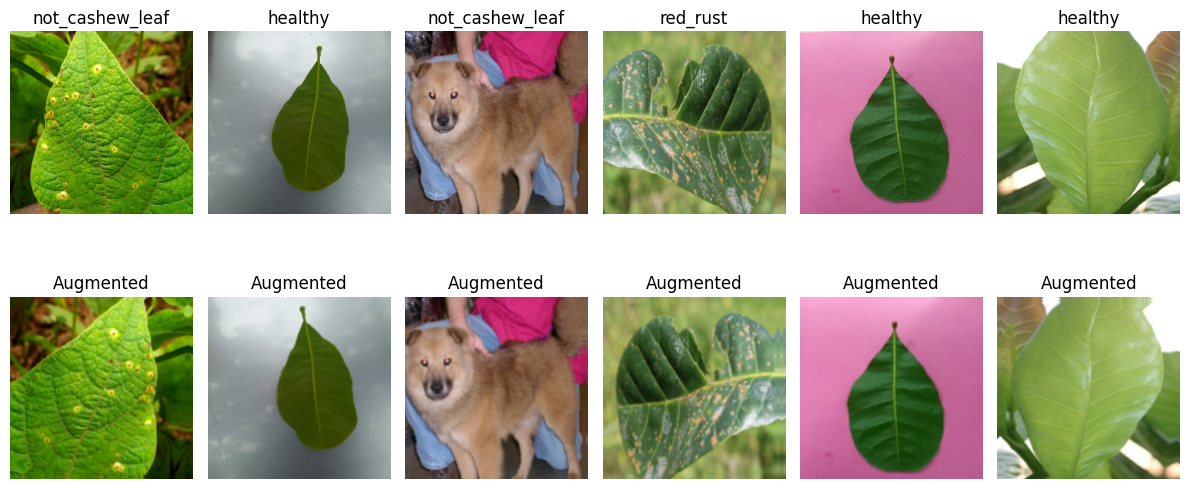

25473

In [12]:

# ============================================================
# 11. AUGMENTATION VISUAL CHECK
# ============================================================

preview_seed = SEEDS[0]

preview_ds = make_dataset(
    train_paths,
    train_labels,
    seed=preview_seed,
    training=True
)

preview_aug = build_data_augmentation(preview_seed)

for images, labels in preview_ds.take(1):

    n = min(6, int(images.shape[0]))

    plt.figure(figsize=(12, 6))

    for i in range(n):

        plt.subplot(2, 6, i + 1)
        plt.imshow(
            tf.cast(
                tf.clip_by_value(images[i], 0, 255),
                tf.uint8
            )
        )
        plt.title(CLASS_NAMES[int(labels[i])])
        plt.axis("off")

        aug_img = preview_aug(
            tf.expand_dims(images[i], 0),
            training=True
        )[0]

        plt.subplot(2, 6, i + 7)
        plt.imshow(
            tf.cast(
                tf.clip_by_value(aug_img, 0, 255),
                tf.uint8
            )
        )
        plt.title("Augmented")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

del preview_ds, preview_aug
gc.collect()


In [13]:

# ============================================================
# 12. SAVE EXPERIMENT CONFIG
# ============================================================

experiment_config = {
    "experiment_id": EXPERIMENT_ID,
    "notebook_version": NOTEBOOK_VERSION,
    "external_holdout_protocol": {
        "archive_name": REAL_HOLDOUT_ARCHIVE_NAME,
        "archive_sha256": REAL_HOLDOUT_ARCHIVE_SHA256,
        "expected_counts": REAL_HOLDOUT_EXPECTED_COUNTS,
        "gate": "RUN_FINAL_TEST and RUN_REAL_HOLDOUT",
        "separate_from_v06_test": True,
        "macro_scope": "true classes with holdout support; currently four",
        "selection_source": "validation only",
    },
    "created_at": datetime.now().isoformat(),

    "dataset": {
        "version": DATASET_VERSION,
        "archive_name": DATASET_ARCHIVE_NAME,
        "archive_file_id": DATASET_ARCHIVE_FILE_ID,
        "path": str(DATASET_PATH),
        "classes": CLASS_NAMES,
        "train_images": len(train_paths),
        "val_images": len(val_paths),
        "test_images": len(test_paths),
        "total_images": len(valid_df),
        "test_set_locked": True,
        "manifest_sha256": DATASET_MANIFEST_SHA256,
        "required_absent_images": REQUIRED_ABSENT_IMAGES,
    },

    "model": {
        "name": MODEL_NAME,
        "training_mode": TRAINING_MODE,
        "weights": PRETRAINED_WEIGHTS,
        "include_top": False,
        "input_size": [IMG_SIZE, IMG_SIZE, 3],
        "head_units": HEAD_UNITS,
        "head_dropout": HEAD_DROPOUT,
        "backbone_call": "x = backbone(x)",
        "forced_training_true": False,
        "batch_norm_momentum": 0.90,
    },

    "training": {
        "seeds": SEEDS,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "optimizer": "Adam",
        "peak_learning_rate": INITIAL_LR,
        "warmup_start_learning_rate": WARMUP_START_LR,
        "minimum_learning_rate": MIN_LR,
        "warmup_epochs": WARMUP_EPOCHS,
        "schedule": "per_batch_linear_warmup_then_cosine",
        "maximum_epochs": MAX_EPOCHS,
        "loss": "SparseCategoricalCrossentropy",
        "class_weight": None,
    },

    "augmentation": AUGMENTATION_CONFIG,

    "callbacks": {
        "checkpoint_selection": CHECKPOINT_SELECTION,
        "checkpoint_type": "weights_only",
        "early_stopping": True,
        "early_stopping_monitor": "val_macro_f1",
        "early_stopping_mode": "max",
        "early_stopping_start_epoch": EARLY_STOPPING_START_EPOCH,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "restore_best_weights": False,
        "reduce_lr_on_plateau": False,
        "lr_logged_per_batch": True,
    },

    "test_protocol": {
        "run_final_test": RUN_FINAL_TEST,
        "final_test_completed": False,
        "same_locked_test_for_all_seeds": True,
        "do_not_select_best_seed_on_test": True,
        "summary": "mean ± sample standard deviation (ddof=1)",
    },


"deployment_protocol": {
    "selection_source": "validation only",
    "selection_metric": "val_macro_f1",
    "tie_break": "lower val_loss",
    "test_used_for_selection": False,
},

"figure_protocol": {
    "comparison_layout": "panel",
    "training_curves": "2 rows x 5 seed columns",
    "confusion_matrices": "1 row x 5 seed columns",
},

"archive": {
    "full_archive": f"{EXPERIMENT_ID}_FULL.zip",
    "analysis_archive": f"{EXPERIMENT_ID}_ANALYSIS.zip",
    "google_drive_target_url": DRIVE_TARGET_URL,
    "google_drive_target_folder_id": DRIVE_TARGET_FOLDER_ID,
},

    "hardware": {
        "gpu_count": len(gpus),
        "strategy": strategy.__class__.__name__,
        "replicas": strategy.num_replicas_in_sync,
    },
}

config_path = OUT_DIR / "experiment_config.json"

if config_path.exists():
    saved_config = json.loads(config_path.read_text(encoding="utf-8"))
    # Compare frozen training/Validation sections before reusing saved results.
    for key in ("dataset", "model", "training", "augmentation", "callbacks"):
        if key not in saved_config or saved_config[key] != experiment_config[key]:
            raise ValueError(f"Saved {key} differs from this notebook. Restore the frozen configuration.")
    experiment_config = saved_config
else:
    config_path.write_text(
        json.dumps(experiment_config, indent=2, ensure_ascii=False), encoding="utf-8"
    )

print("Saved:", config_path)


drive_target_path = OUT_DIR / "drive_target.json"
drive_target_path.write_text(
    json.dumps(
        {
            "folder_url": DRIVE_TARGET_URL,
            "folder_id": DRIVE_TARGET_FOLDER_ID,
            "archive_name": f"{EXPERIMENT_ID}_FULL.zip",
        },
        indent=2,
    ),
    encoding="utf-8",
)
print("Saved:", drive_target_path)


Saved: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008/experiment_config.json
Saved: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008/drive_target.json


## Locked real-world holdout (external Test)

Upload this notebook alone to Colab: the shared evaluator is embedded below, so no
additional Python module upload is necessary. On Colab the ZIP is read from
`MyDrive/Cashew_Leaf_model_result/Dataset/RL_Cashew_holdout.zip`.
Set `REAL_HOLDOUT_ARCHIVE_OVERRIDE` if your mounted location differs.
This preflight runs only when both Test flags permit it, before any Test prediction.

When Final Test is already enabled, this data-only check runs before costly training.
If enabling Test after training, run this preflight cell again before the Test drivers.


In [14]:
"""Locked external classification evaluation; embedded in standalone notebooks.

This file has no training code. Holdout labels never select checkpoints or seeds.
"""

import hashlib
import json
import os
import stat
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score


REAL_HOLDOUT_HELPER_VERSION = "006.1"
REAL_HOLDOUT_CMAP = LinearSegmentedColormap.from_list(
    "real_holdout_readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)


def holdout_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest().upper()


def resolve_holdout_archive(archive_name, override=None):
    if override is not None:
        candidate = Path(override)
        if not candidate.is_file():
            raise FileNotFoundError(candidate)
        return candidate
    if Path("/content/drive/MyDrive").is_dir():
        candidate = Path("/content/drive/MyDrive/Cashew_Leaf_model_result/Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if os.name == "nt":
        candidate = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if Path("/kaggle/input").is_dir():
        candidates = sorted(Path("/kaggle/input").rglob(archive_name))
        if len(candidates) == 1:
            return candidates[0]
    raise FileNotFoundError(
        f"Cannot uniquely locate {archive_name}. Set REAL_HOLDOUT_ARCHIVE_OVERRIDE "
        "to the mounted ZIP path; on Colab add the supplied Dataset folder to My Drive."
    )


def prepare_real_holdout(archive_path, extraction_dir, class_names, expected_sha256,
                         expected_counts, reference_rows, audit_dir):
    """Verify the frozen archive, labels, decoding and byte overlap with V05.

    reference_rows: dictionaries with path/split and optional existing sha256.
    Exact-byte checking does not establish independence of near-duplicate photos.
    """
    archive_path, extraction_dir, audit_dir = map(Path, (archive_path, extraction_dir, audit_dir))
    actual_hash = holdout_sha256(archive_path)
    if actual_hash != expected_sha256.upper():
        raise ValueError(f"Holdout archive changed: {actual_hash}; expected {expected_sha256}.")
    marker = extraction_dir / ".archive_sha256"
    if extraction_dir.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != actual_hash:
            raise FileExistsError(f"Unverified extraction: {extraction_dir}; choose a new directory.")
    else:
        with zipfile.ZipFile(archive_path) as archive:
            resolved_root = extraction_dir.resolve()
            for member in archive.infolist():
                target = (extraction_dir / member.filename.replace("\\", "/")).resolve()
                is_symlink = stat.S_ISLNK(member.external_attr >> 16)
                if is_symlink or (target != resolved_root and resolved_root not in target.parents):
                    raise ValueError(f"Unsafe ZIP member: {member.filename}")
            extraction_dir.mkdir(parents=True)
            archive.extractall(extraction_dir)
        marker.write_text(actual_hash, encoding="utf-8")

    dataset_root = extraction_dir / "RL_Cashew_holdout"
    if not dataset_root.is_dir():
        raise FileNotFoundError(dataset_root)
    found_classes = sorted(p.name for p in dataset_root.iterdir() if p.is_dir())
    if found_classes != sorted(expected_counts) or not set(found_classes).issubset(class_names):
        raise ValueError(f"Unexpected holdout class folders: {found_classes}")
    rows = []
    for label, name in enumerate(class_names):
        class_dir = dataset_root / name
        files = sorted(p for p in class_dir.rglob("*") if p.is_file()) if class_dir.is_dir() else []
        if len(files) != expected_counts.get(name, 0):
            raise ValueError(f"Unexpected holdout count for {name}: {len(files)}")
        for image_path in files:
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                raise ValueError(f"Unsupported holdout image: {image_path}")
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.convert("RGB").load()
            rows.append({"path": str(image_path), "relative_path": image_path.relative_to(dataset_root).as_posix(),
                         "class": name, "label": label, "sha256": holdout_sha256(image_path)})
    manifest = pd.DataFrame(rows)
    if manifest.empty or manifest["sha256"].duplicated().any():
        raise ValueError("Holdout is empty or contains duplicate image bytes.")
    # A marker alone is insufficient: verify cached extraction bytes against the ZIP.
    with zipfile.ZipFile(archive_path) as frozen_archive:
        for row in rows:
            digest = hashlib.sha256()
            with frozen_archive.open("RL_Cashew_holdout/" + row["relative_path"]) as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
            if digest.hexdigest().upper() != row["sha256"]:
                raise ValueError(f"Cached holdout extraction changed: {row['relative_path']}")
    audit_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(audit_dir / "dataset_manifest.csv", index=False)

    references = list(reference_rows)
    if not references or not {"train", "val", "test"}.issubset({r["split"] for r in references}):
        raise ValueError("Overlap audit needs the full train/val/test V05 reference manifest.")
    holdout_hashes = set(manifest["sha256"])
    overlaps = []
    reference_digest = hashlib.sha256()
    for row in references:
        digest = row.get("sha256") or holdout_sha256(row["path"])
        digest = digest.upper()
        identity = row.get("relative_path", str(row["path"]))
        reference_digest.update(f"{row['split']}\0{identity}\0{digest}\n".encode("utf-8"))
        if digest in holdout_hashes:
            overlaps.append({"reference_path": str(row["path"]), "split": row["split"], "sha256": digest})
    present = [name for name in class_names if expected_counts.get(name, 0) > 0]
    audit = {"archive_sha256": actual_hash, "archive_name": archive_path.name,
             "manifest_sha256": hashlib.sha256(manifest[["relative_path", "class", "label", "sha256"]]
                 .to_csv(index=False).encode()).hexdigest(),
             "counts": {name: expected_counts.get(name, 0) for name in class_names},
             "images": len(manifest), "present_classes": present,
             "unsupported_classes": [name for name in class_names if name not in present],
             "reference_images_checked": len(references), "reference_fingerprint": reference_digest.hexdigest(),
             "byte_overlap_count": len(overlaps), "byte_overlaps": overlaps,
             "limitation": "Byte audit only; near-duplicate photos and shared trees/sessions need a separate audit."}
    (audit_dir / "dataset_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    if overlaps:
        raise ValueError("Real holdout overlaps V05 by exact bytes; inspect dataset_audit.json before evaluation.")
    print("Real holdout:", len(manifest), "images; present classes:", present)
    print("Not evaluated (no true examples):", audit["unsupported_classes"])
    return manifest, audit


def save_real_holdout_seed(manifest, probabilities, class_names, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(manifest), len(class_names)) or not np.isfinite(probabilities).all():
        raise ValueError("Holdout predictions have invalid shape or non-finite values.")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Holdout evaluator expects probabilities, not logits.")
    y_true = manifest["label"].to_numpy(dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    present_ids = sorted(set(y_true.tolist()))
    all_ids = list(range(len(class_names)))
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision_present_classes": float(precision_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_recall_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "balanced_accuracy_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "images": len(manifest), "macro_class_count": len(present_ids),
    }
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=all_ids,
        target_names=class_names, output_dict=True, zero_division=0)).transpose()
    per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    per_class["evaluated"] = per_class["support"] > 0
    # No evidence for unsupported true classes: don't present placeholder zeros as performance.
    per_class.loc[~per_class["evaluated"], ["precision", "recall", "f1-score"]] = np.nan
    per_class.to_csv(output_dir / "per_class_metrics.csv", index_label="class")
    readable_report = per_class.copy()
    readable_report["scope"] = np.where(readable_report["evaluated"], "true class present", "not evaluated: zero true support")
    readable_report.loc["macro avg (present classes)"] = [
        result["macro_precision_present_classes"], result["macro_recall_present_classes"],
        result["macro_f1_present_classes"], len(manifest), True,
        f"{len(present_ids)} supported true classes only",
    ]
    readable_report.loc["weighted avg"] = [
        report.loc["weighted avg", "precision"], report.loc["weighted avg", "recall"],
        report.loc["weighted avg", "f1-score"], len(manifest), True, "weighted by true support",
    ]
    readable_report.to_csv(output_dir / "classification_report.csv", index_label="class")
    predictions = manifest[["relative_path", "class", "label"]].copy()
    predictions["predicted_label"] = y_pred
    predictions["predicted_class"] = [class_names[i] for i in y_pred]
    predictions["confidence"] = probabilities.max(axis=1)
    predictions["correct"] = y_true == y_pred
    for label, name in enumerate(class_names):
        predictions[f"probability_{name}"] = probabilities[:, label]
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    matrix = confusion_matrix(y_true, y_pred, labels=all_ids)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=class_names, columns=class_names).to_csv(output_dir / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
        ax.set_facecolor("white")
        ax.imshow(values, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                  vmax=1 if normalized else max(int(matrix.max()), 1))
        ax.set_xticks(all_ids, class_names, rotation=40, ha="right", color="black")
        ax.set_yticks(all_ids, class_names, color="black")
        ax.set_xlabel("Predicted class", color="black")
        ax.set_ylabel("True class", color="black")
        ax.set_title("Real holdout" + (" (row normalized)" if normalized else ""), color="black")
        for row in all_ids:
            for col in all_ids:
                text = f"{values[row, col]:.2f}" if normalized else str(int(values[row, col]))
                if normalized and row not in present_ids:
                    text = "N/A"
                ax.text(col, row, text, ha="center", va="center", color="black")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def evaluate_real_holdout(manifest, audit, class_names, seeds, validation_results,
                          checkpoints, load_model, make_dataset, clear_session,
                          output_dir, outputs_are_logits=False):
    """Freeze all checkpoints and validation selection BEFORE any prediction.

    Completed evaluations are read back, not repeated. Interrupted evaluations
    may resume only with the same checkpoint, validation and archive fingerprints.
    """
    output_dir = Path(output_dir)
    seeds = [int(seed) for seed in seeds]
    validation_results = validation_results.copy()
    if validation_results["seed"].tolist() != seeds:
        raise ValueError("Holdout evaluation requires completed, ordered validation for every seed.")
    if not np.isfinite(validation_results[["val_macro_f1", "val_loss"]].to_numpy()).all():
        raise ValueError("Validation selection metrics are incomplete.")
    ranked = validation_results.sort_values(["val_macro_f1", "val_loss", "seed"], ascending=[False, True, True])
    deployment_seed = int(ranked.iloc[0]["seed"])
    checkpoint_hashes = {str(seed): holdout_sha256(checkpoints[seed]) for seed in seeds}
    lock = {"helper_version": REAL_HOLDOUT_HELPER_VERSION, "archive_sha256": audit["archive_sha256"],
            "manifest_sha256": audit["manifest_sha256"],
            "reference_fingerprint": audit["reference_fingerprint"], "seeds": seeds,
            "checkpoint_sha256": checkpoint_hashes, "deployment_seed": deployment_seed,
            # Canonical float precision avoids false lock changes on CSV reload.
            "validation_sha256": hashlib.sha256(validation_results.to_csv(index=False, float_format="%.12g").encode()).hexdigest(),
            "model_classes": class_names, "macro_classes": audit["present_classes"],
            "selection_source": "validation only; macro F1, val_loss, seed tie-break",
            "outputs_are_logits": outputs_are_logits}
    lock_path = output_dir / "evaluation_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text(encoding="utf-8")) != lock:
            raise ValueError("Holdout lock changed. Do not retune using holdout or overwrite its results.")
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        lock_path.write_text(json.dumps(lock, indent=2), encoding="utf-8")
    aggregate_dir = output_dir / "aggregate"
    aggregate_dir.mkdir(exist_ok=True)
    results_path = aggregate_dir / "real_holdout_results_5seeds.csv"
    if (output_dir / "evaluation_completed.json").exists():
        print("Real holdout already completed; reading frozen results, not running predictions again.")
        return pd.read_csv(results_path)
    result_rows = []
    for seed in seeds:
        seed_dir = output_dir / f"seed_{seed}"
        completed_path = seed_dir / "evaluation_completed.json"
        if completed_path.exists():
            row = json.loads(completed_path.read_text(encoding="utf-8"))
        else:
            clear_session()
            model = load_model(seed)
            dataset = make_dataset(manifest)
            start = time.perf_counter()
            scores = np.asarray(model.predict(dataset, verbose=0))
            prediction_seconds = time.perf_counter() - start
            if outputs_are_logits:
                exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
                scores = exponentials / exponentials.sum(axis=1, keepdims=True)
            row = {"seed": seed, **save_real_holdout_seed(manifest, scores, class_names, seed_dir),
                   "prediction_seconds_including_input_pipeline": prediction_seconds}
            completed_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
            del model, scores, dataset
            clear_session()
        result_rows.append(row)
    results = pd.DataFrame(result_rows)
    results.to_csv(results_path, index=False)
    metric_columns = [c for c in results if c not in {"seed", "images", "macro_class_count"}]
    results[metric_columns].agg(["mean", "std"]).transpose().to_csv(aggregate_dir / "real_holdout_mean_std.csv")
    per_class = pd.concat([pd.read_csv(output_dir / f"seed_{seed}" / "per_class_metrics.csv")
                          .assign(seed=seed) for seed in seeds], ignore_index=True)
    per_class.groupby("class")[["precision", "recall", "f1-score"]].agg(["mean", "std"]).to_csv(
        aggregate_dir / "per_class_real_holdout_mean_std.csv")
    deployment_result = next(row for row in result_rows if row["seed"] == deployment_seed)
    (aggregate_dir / "deployment_seed_result.json").write_text(json.dumps({
        "selection_source": "validation only, fixed before holdout", "result": deployment_result,
    }, indent=2), encoding="utf-8")
    (output_dir / "evaluation_completed.json").write_text(json.dumps({
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": "No model or seed selection on holdout. SD measures training-seed variability, not sampling uncertainty.",
    }, indent=2), encoding="utf-8")
    print("Real holdout results (macro metrics over supported true classes only):")
    print(results)
    return results

# --- Notebook-specific real holdout preflight (no prediction/training here) ---
if RUN_FINAL_TEST and RUN_REAL_HOLDOUT:
    holdout_archive = resolve_holdout_archive(REAL_HOLDOUT_ARCHIVE_NAME, REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    holdout_reference_rows = valid_df.assign(
        relative_path=valid_df["path"].map(lambda path: Path(path).relative_to(DATASET_PATH).as_posix())
    ).to_dict("records")
    holdout_out_dir = OUT_DIR / "real_holdout"
    # Use runtime-local storage, not the Drive result directory, for images.
    if Path("/content").is_dir():
        holdout_extract_dir = Path("/content/real_holdout_006") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    elif Path("/kaggle/working").is_dir():
        holdout_extract_dir = Path("/kaggle/working/real_holdout_006") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    else:
        import tempfile
        holdout_extract_dir = Path(tempfile.gettempdir()) / "cashew_real_holdout_006" / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    real_holdout_manifest, real_holdout_audit = prepare_real_holdout(
        holdout_archive, holdout_extract_dir, CLASS_NAMES,
        REAL_HOLDOUT_ARCHIVE_SHA256, REAL_HOLDOUT_EXPECTED_COUNTS,
        holdout_reference_rows, holdout_out_dir,
    )
else:
    print("Real-world holdout remains locked; no holdout extraction/evaluation runs.")


Real-world holdout remains locked; no holdout extraction/evaluation runs.


# Train 5 Seeds

Each seed starts from a fresh deterministic initialization and runs for up to
30 epochs. LR is updated per batch: three-epoch linear warmup from 1e-5 to
3e-4, then cosine decay toward 1e-6. EarlyStopping monitors Validation
macro-F1 from epoch 19 with patience 8, so it can stop a stagnant seed late
in the schedule. ReduceLROnPlateau is disabled.

The saved checkpoint maximizes Validation macro-F1. Exact macro-F1 ties use
lower Validation loss, then the earlier epoch. Test remains locked.


In [15]:
# ============================================================
# 13. TRAIN ALL 5 SEEDS - FROZEN A_4 RECIPE
# ============================================================
import math

if RUN_TRAINING and RUN_FINAL_TEST:
    raise RuntimeError("Training and Final Test cannot be enabled in the same Run All session")

STEPS_PER_EPOCH = math.ceil(len(train_paths) / BATCH_SIZE)
TOTAL_STEPS = MAX_EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS = WARMUP_EPOCHS * STEPS_PER_EPOCH


def lr_at_global_step(step):
    if not 0 <= step < TOTAL_STEPS:
        raise ValueError(f"LR step {step} outside [0, {TOTAL_STEPS})")
    if step < WARMUP_STEPS:
        return WARMUP_START_LR + (INITIAL_LR - WARMUP_START_LR) * ((step + 1) / WARMUP_STEPS)
    decay_steps = max(1, TOTAL_STEPS - WARMUP_STEPS - 1)
    progress = (step - WARMUP_STEPS) / decay_steps
    return MIN_LR + 0.5 * (INITIAL_LR - MIN_LR) * (1.0 + math.cos(math.pi * progress))


class ValidationMacroF1Checkpoint(tf.keras.callbacks.Callback):
    def __init__(self, val_dataset, val_targets, checkpoint_path, log_dir):
        super().__init__()
        self.val_dataset = val_dataset
        self.val_targets = np.asarray(val_targets, dtype=np.int32)
        self.checkpoint_path = checkpoint_path
        self.log_dir = log_dir
        self.global_step = 0
        self.epoch_number = 0
        self.epoch_rows = []
        self.lr_rows = []
        self.best_f1 = -np.inf
        self.best_loss = np.inf

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_number = epoch + 1

    def on_train_batch_begin(self, batch, logs=None):
        optimizer_step = int(self.model.optimizer.iterations.numpy())
        if optimizer_step != self.global_step:
            raise RuntimeError("Optimizer iteration and LR schedule step disagree")
        requested_lr = lr_at_global_step(self.global_step)
        self.model.optimizer.learning_rate.assign(requested_lr)
        actual_lr = float(self.model.optimizer.learning_rate.numpy())
        if not np.isclose(actual_lr, requested_lr, rtol=1e-6, atol=1e-12):
            raise RuntimeError("Optimizer did not apply the requested learning rate")
        self.lr_rows.append({
            "epoch": self.epoch_number,
            "batch": int(batch + 1),
            "global_step": self.global_step,
            "optimizer_iteration": optimizer_step,
            "lr_requested": float(requested_lr),
            "learning_rate": actual_lr,
        })

    def on_train_batch_end(self, batch, logs=None):
        self.global_step += 1
        if int(self.model.optimizer.iterations.numpy()) != self.global_step:
            raise RuntimeError("Expected exactly one optimizer update per batch")

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        expected_steps = (epoch + 1) * STEPS_PER_EPOCH
        if self.global_step != expected_steps:
            raise RuntimeError("Observed batch count differs from the frozen LR schedule")
        probabilities = self.model.predict(self.val_dataset, verbose=0)
        if probabilities.shape != (len(self.val_targets), NUM_CLASSES) or not np.isfinite(probabilities).all():
            raise RuntimeError("Invalid Validation predictions")
        predictions = np.argmax(probabilities, axis=1)
        val_macro_f1 = float(f1_score(
            self.val_targets, predictions, average="macro",
            labels=np.arange(NUM_CLASSES), zero_division=0,
        ))
        val_loss = float(logs["val_loss"])
        epoch_lrs = [row["learning_rate"] for row in self.lr_rows if row["epoch"] == epoch + 1]
        row = {
            "epoch": int(epoch + 1),
            "accuracy": float(logs["accuracy"]),
            "loss": float(logs["loss"]),
            "val_accuracy": float(logs["val_accuracy"]),
            "val_loss": val_loss,
            "val_macro_f1": val_macro_f1,
            "lr_first_batch": float(epoch_lrs[0]),
            "lr_last_batch": float(epoch_lrs[-1]),
        }
        if not np.isfinite(list(row.values())).all():
            raise RuntimeError("Non-finite metric detected")
        self.epoch_rows.append(row)
        logs["val_macro_f1"] = val_macro_f1
        logs["learning_rate"] = row["lr_last_batch"]
        pd.DataFrame(self.epoch_rows).to_csv(self.log_dir / "history.csv", index=False)
        pd.DataFrame(self.lr_rows).to_csv(self.log_dir / "lr_batch_log.csv", index=False)
        improved = (
            val_macro_f1 > self.best_f1 + 1e-12 or
            (abs(val_macro_f1 - self.best_f1) <= 1e-12 and val_loss < self.best_loss)
        )
        if improved:
            self.best_f1, self.best_loss = val_macro_f1, val_loss
            self.model.save_weights(self.checkpoint_path)
            print(f"Saved best macro-F1 checkpoint: {val_macro_f1:.6f} at epoch {epoch + 1}")
        print(f"Validation macro-F1: {val_macro_f1:.6f}")


training_rows = []
validation_rows = []

for run_index, seed in enumerate(SEEDS if RUN_TRAINING else [], start=1):
    print("\n" + "=" * 80)
    print(f"RUN {run_index}/{len(SEEDS)} - SEED {seed}")
    print("=" * 80)
    tf.keras.backend.clear_session()
    gc.collect()
    set_global_seed(seed)

    seed_dir = OUT_DIR / f"seed_{seed}"
    checkpoint_dir = seed_dir / "checkpoints"
    log_dir = seed_dir / "logs"
    figure_dir = seed_dir / "figures"
    validation_dir = seed_dir / "validation"
    for folder in [checkpoint_dir, log_dir, figure_dir, validation_dir]:
        folder.mkdir(parents=True, exist_ok=True)

    best_weights_path = checkpoint_dir / f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5"
    if any(path.is_file() for path in seed_dir.rglob("*")):
        raise FileExistsError(f"Refusing to overwrite partial or completed outputs for seed {seed}: {seed_dir}")

    train_ds = make_dataset(train_paths, train_labels, seed=seed, training=True)
    val_ds = make_dataset(val_paths, val_labels, seed=seed, training=False)

    with strategy.scope():
        model = build_densenet121_model(seed)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=WARMUP_START_LR),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(),
            metrics=["accuracy"], steps_per_execution=1, jit_compile=False,
        )

    summary_lines = []
    model.summary(print_fn=lambda line: summary_lines.append(line))
    (seed_dir / "model_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")
    total_params = int(model.count_params())
    trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
    non_trainable_params = total_params - trainable_params

    audit = ValidationMacroF1Checkpoint(val_ds, val_labels, best_weights_path, log_dir)
    callbacks = [
        audit,
        tf.keras.callbacks.EarlyStopping(
            monitor="val_macro_f1", mode="max", min_delta=0.0,
            patience=EARLY_STOPPING_PATIENCE,
            start_from_epoch=EARLY_STOPPING_START_EPOCH - 1,
            restore_best_weights=False, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(str(log_dir / "training_log.csv")),
    ]
    start_time = time.perf_counter()
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
        callbacks=callbacks, verbose=1,
    )
    training_time_seconds = time.perf_counter() - start_time
    history_df = pd.DataFrame(audit.epoch_rows)
    actual_epochs = len(history_df)
    if not EARLY_STOPPING_START_EPOCH <= actual_epochs <= MAX_EPOCHS:
        raise RuntimeError(f"Seed {seed} stopped outside the permitted epoch range")
    if audit.global_step != actual_epochs * STEPS_PER_EPOCH:
        raise RuntimeError(f"Seed {seed} has an incomplete optimizer-step trace")
    if not best_weights_path.is_file():
        raise FileNotFoundError(f"Macro-F1 checkpoint was not created: {best_weights_path}")
    expected_steps = list(range(audit.global_step))
    if [row["global_step"] for row in audit.lr_rows] != expected_steps:
        raise RuntimeError("LR trace is incomplete or out of order")

    best = history_df.sort_values(
        ["val_macro_f1", "val_loss", "epoch"], ascending=[False, True, True]
    ).iloc[0]
    best_epoch = int(best["epoch"])
    best_val_loss_history = float(best["val_loss"])
    best_val_accuracy_history = float(best["val_accuracy"])
    best_val_macro_f1_history = float(best["val_macro_f1"])

    for metric, filename, ylabel in [
        ("accuracy", "accuracy_curve.png", "Accuracy"),
        ("loss", "loss_curve.png", "Loss"),
    ]:
        plt.figure(figsize=(8, 5))
        plt.plot(history_df["epoch"], history_df[metric], label="Train")
        plt.plot(history_df["epoch"], history_df[f"val_{metric}"], label="Validation")
        plt.axvline(best_epoch, linestyle="--", label=f"Best macro-F1 epoch = {best_epoch}")
        plt.xlabel("Epoch"); plt.ylabel(ylabel)
        plt.title(f"DenseNet121 Scratch - Seed {seed} - {ylabel}")
        plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
        plt.savefig(figure_dir / filename, dpi=200, bbox_inches="tight")
        plt.close()
    plt.figure(figsize=(8, 5))
    plt.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o")
    plt.axvline(best_epoch, linestyle="--", label=f"Best epoch = {best_epoch}")
    plt.xlabel("Epoch"); plt.ylabel("Validation macro-F1")
    plt.title(f"DenseNet121 Scratch - Seed {seed} - Validation macro-F1")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(figure_dir / "val_macro_f1_curve.png", dpi=200, bbox_inches="tight")
    plt.close()

    model.load_weights(best_weights_path)
    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
    y_val_prob = model.predict(val_ds, verbose=0)
    y_val_true = np.asarray(val_labels, dtype=np.int32)
    y_val_pred = np.argmax(y_val_prob, axis=1)
    y_val_conf = np.max(y_val_prob, axis=1)
    if len(y_val_pred) != len(y_val_true):
        raise RuntimeError("Validation prediction count mismatch")
    val_metrics = {
        "seed": seed,
        "selected_epoch": best_epoch,
        "selection_metric": "val_macro_f1",
        "val_loss": float(val_loss),
        "val_accuracy": float(accuracy_score(y_val_true, y_val_pred)),
        "val_macro_precision": float(precision_score(y_val_true, y_val_pred, average="macro", zero_division=0)),
        "val_macro_recall": float(recall_score(y_val_true, y_val_pred, average="macro", zero_division=0)),
        "val_macro_f1": float(f1_score(y_val_true, y_val_pred, average="macro", labels=np.arange(NUM_CLASSES), zero_division=0)),
        "val_balanced_accuracy": float(balanced_accuracy_score(y_val_true, y_val_pred)),
    }
    if not np.isclose(val_metrics["val_macro_f1"], best_val_macro_f1_history, atol=1e-7):
        raise RuntimeError("Reloaded checkpoint macro-F1 differs from the selected epoch")
    validation_rows.append(val_metrics)

    val_report_df = pd.DataFrame(classification_report(
        y_val_true, y_val_pred, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )).transpose()
    val_report_df.to_csv(validation_dir / "classification_report.csv")
    val_cm = confusion_matrix(y_val_true, y_val_pred)
    val_cm_norm = confusion_matrix(y_val_true, y_val_pred, normalize="true")
    pd.DataFrame(val_cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(validation_dir / "confusion_matrix.csv")
    pd.DataFrame(val_cm_norm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(validation_dir / "confusion_matrix_normalized.csv")
    fig, ax = plt.subplots(figsize=(8, 7))
    matrix_display = ConfusionMatrixDisplay(val_cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap=MATRIX_CMAP, values_format="d", colorbar=False,
    )
    for label in matrix_display.text_.ravel():
        label.set_color("black")
    plt.title(f"Validation Confusion Matrix - Seed {seed}")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    plt.savefig(validation_dir / "confusion_matrix.png", dpi=200, bbox_inches="tight")
    plt.close()

    val_predictions_df = pd.DataFrame({
        "filename": val_meta["path"],
        "true_label": [CLASS_NAMES[int(i)] for i in y_val_true],
        "predicted_label": [CLASS_NAMES[int(i)] for i in y_val_pred],
        "confidence": y_val_conf,
        "correct": y_val_true == y_val_pred,
    })
    for class_index, class_name in enumerate(CLASS_NAMES):
        val_predictions_df[f"prob_{class_name}"] = y_val_prob[:, class_index]
    val_predictions_df.to_csv(validation_dir / "predictions.csv", index=False)

    row = {
        "seed": seed, "actual_epochs": actual_epochs,
        "schedule_completed": actual_epochs == MAX_EPOCHS,
        "stopped_early": actual_epochs < MAX_EPOCHS,
        "optimizer_steps": audit.global_step, "best_epoch": best_epoch,
        "selection_metric": "val_macro_f1",
        "best_val_macro_f1_history": best_val_macro_f1_history,
        "selected_val_loss_history": best_val_loss_history,
        "selected_val_accuracy_history": best_val_accuracy_history,
        "checkpoint_val_loss": float(val_loss),
        "checkpoint_val_accuracy": val_metrics["val_accuracy"],
        "checkpoint_val_macro_f1": val_metrics["val_macro_f1"],
        "checkpoint_val_balanced_accuracy": val_metrics["val_balanced_accuracy"],
        "training_time_seconds": float(training_time_seconds),
        "total_parameters": total_params, "trainable_parameters": trainable_params,
        "non_trainable_parameters": non_trainable_params,
        "best_weights_path": str(best_weights_path),
        "best_weights_size_mb": float(best_weights_path.stat().st_size / (1024 ** 2)),
        "lr_first": float(audit.lr_rows[0]["learning_rate"]),
        "lr_final": float(audit.lr_rows[-1]["learning_rate"]),
    }
    training_rows.append(row)
    (seed_dir / "training_summary.json").write_text(json.dumps(row, indent=2), encoding="utf-8")
    print("\nSeed summary:")
    print(json.dumps(row, indent=2))
    del model, train_ds, val_ds, history
    tf.keras.backend.clear_session()
    gc.collect()

if RUN_TRAINING:
    training_summary_df = pd.DataFrame(training_rows)
    validation_results_df = pd.DataFrame(validation_rows)
    if training_summary_df["seed"].tolist() != SEEDS:
        raise RuntimeError("Not all five seeds completed")
    training_summary_df.to_csv(AGGREGATE_DIR / "training_summary_5seeds.csv", index=False)
    validation_results_df.to_csv(AGGREGATE_DIR / "validation_results_5seeds.csv", index=False)
else:
    training_summary_df = pd.read_csv(AGGREGATE_DIR / "training_summary_5seeds.csv")
    validation_results_df = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv")
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise ValueError("Saved training/validation results must contain all configured seeds in order")

training_times = training_summary_df["training_time_seconds"]
training_time_summary = pd.DataFrame({
    "metric": ["training_time_seconds", "training_time_minutes"],
    "mean": [training_times.mean(), training_times.mean() / 60],
    "std": [training_times.std(ddof=1), training_times.std(ddof=1) / 60],
    "total": [training_times.sum(), training_times.sum() / 60],
})
training_time_summary.to_csv(AGGREGATE_DIR / "training_time_mean_std_summary.csv", index=False)
print("\nTraining time across seeds:"); display(training_time_summary)
print("\nTraining summary:"); display(training_summary_df)
print("\nValidation metrics:"); display(validation_results_df)



RUN 1/5 - SEED 42
Global seed set to: 42
Global seed set to: 42


Epoch 1/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.4586 - loss: 1.5099Saved best macro-F1 checkpoint: 0.641392 at epoch 1
Validation macro-F1: 0.641392
151/151 ━━━━━━━━━━━━━━━━━━━━ 123s 538ms/step - accuracy: 0.5934 - loss: 1.1079 - val_accuracy: 0.6717 - val_loss: 0.9167 - val_macro_f1: 0.6414 - learning_rate: 1.0667e-04
Epoch 2/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.7122 - loss: 0.7958Validation macro-F1: 0.598620
151/151 ━━━━━━━━━━━━━━━━━━━━ 67s 444ms/step - accuracy: 0.7181 - loss: 0.7710 - val_accuracy: 0.6674 - val_loss: 0.9615 - val_macro_f1: 0.5986 - learning_rate: 2.0333e-04
Epoch 3/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.7530 - loss: 0.6916Validation macro-F1: 0.601844
151/151 ━━━━━━━━━━━━━━━━━━━━ 67s 444ms/step - accuracy: 0.7606 - loss: 0.6727 - val_accuracy: 0.6559 - val_loss: 1.2196 - val_macro_f1: 0.6018 - learning_rate: 3.0000e-04
Epoch 4/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.7826 - loss: 0.

Epoch 1/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.5203 - loss: 1.2572Saved best macro-F1 checkpoint: 0.665767 at epoch 1
Validation macro-F1: 0.665767
151/151 ━━━━━━━━━━━━━━━━━━━━ 119s 533ms/step - accuracy: 0.6155 - loss: 1.0220 - val_accuracy: 0.7068 - val_loss: 0.7578 - val_macro_f1: 0.6658 - learning_rate: 1.0667e-04
Epoch 2/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.7405 - loss: 0.7457Validation macro-F1: 0.641332
151/151 ━━━━━━━━━━━━━━━━━━━━ 67s 445ms/step - accuracy: 0.7418 - loss: 0.7365 - val_accuracy: 0.6853 - val_loss: 0.7833 - val_macro_f1: 0.6413 - learning_rate: 2.0333e-04
Epoch 3/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.7502 - loss: 0.6824Validation macro-F1: 0.493495
151/151 ━━━━━━━━━━━━━━━━━━━━ 67s 446ms/step - accuracy: 0.7519 - loss: 0.6745 - val_accuracy: 0.5534 - val_loss: 1.3839 - val_macro_f1: 0.4935 - learning_rate: 3.0000e-04
Epoch 4/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.7662 - loss: 0.

Epoch 1/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - accuracy: 0.5021 - loss: 1.3362Saved best macro-F1 checkpoint: 0.582304 at epoch 1
Validation macro-F1: 0.582304
151/151 ━━━━━━━━━━━━━━━━━━━━ 120s 533ms/step - accuracy: 0.6087 - loss: 1.0779 - val_accuracy: 0.5935 - val_loss: 1.1840 - val_macro_f1: 0.5823 - learning_rate: 1.0667e-04
Epoch 2/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.7207 - loss: 0.7819Validation macro-F1: 0.543282
151/151 ━━━━━━━━━━━━━━━━━━━━ 67s 444ms/step - accuracy: 0.7283 - loss: 0.7596 - val_accuracy: 0.6043 - val_loss: 1.4229 - val_macro_f1: 0.5433 - learning_rate: 2.0333e-04
Epoch 3/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.7581 - loss: 0.6688Saved best macro-F1 checkpoint: 0.684086 at epoch 3
Validation macro-F1: 0.684086
151/151 ━━━━━━━━━━━━━━━━━━━━ 71s 472ms/step - accuracy: 0.7517 - loss: 0.6831 - val_accuracy: 0.7039 - val_loss: 0.8772 - val_macro_f1: 0.6841 - learning_rate: 3.0000e-04
Epoch 4/30
151/151 ━━━━━━━━━━━━

Epoch 1/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.5090 - loss: 1.3228Saved best macro-F1 checkpoint: 0.690701 at epoch 1
Validation macro-F1: 0.690701
151/151 ━━━━━━━━━━━━━━━━━━━━ 120s 551ms/step - accuracy: 0.6145 - loss: 1.0628 - val_accuracy: 0.7075 - val_loss: 0.8449 - val_macro_f1: 0.6907 - learning_rate: 1.0667e-04
Epoch 2/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.7297 - loss: 0.7790Validation macro-F1: 0.582278
151/151 ━━━━━━━━━━━━━━━━━━━━ 67s 446ms/step - accuracy: 0.7196 - loss: 0.7981 - val_accuracy: 0.6351 - val_loss: 0.9496 - val_macro_f1: 0.5823 - learning_rate: 2.0333e-04
Epoch 3/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.7490 - loss: 0.7099Validation macro-F1: 0.587495
151/151 ━━━━━━━━━━━━━━━━━━━━ 68s 448ms/step - accuracy: 0.7567 - loss: 0.6976 - val_accuracy: 0.6538 - val_loss: 1.1317 - val_macro_f1: 0.5875 - learning_rate: 3.0000e-04
Epoch 4/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.7744 - loss: 0.

...

,metric,mean,std,total
0,training_time_seconds,2112.344770,12.395411,10561.723851
1,training_time_minutes,35.205746,0.206590,176.028731



Training summary:


,seed,actual_epochs,schedule_completed,stopped_early,optimizer_steps,best_epoch,selection_metric,best_val_macro_f1_history,selected_val_loss_history,selected_val_accuracy_history,...,checkpoint_val_macro_f1,checkpoint_val_balanced_accuracy,training_time_seconds,total_parameters,trainable_parameters,non_trainable_parameters,best_weights_path,best_weights_size_mb,lr_first,lr_final
0,42,30,True,False,4530,30,val_macro_f1,0.930856,0.236293,0.935484,...,0.930856,0.927923,2125.556508,7566917,7482245,84672,/content/drive/MyDrive/Cashew_Leaf_model_resul...,87.296593,0.000011,1.000000e-06
1,123,30,True,False,4530,24,val_macro_f1,0.913688,0.241389,0.916129,...,0.913688,0.908691,2104.127725,7566917,7482245,84672,/content/drive/MyDrive/Cashew_Leaf_model_resul...,87.296593,0.000011,1.000000e-06
2,2026,30,True,False,4530,22,val_macro_f1,0.927508,0.231589,0.930466,...,0.927508,0.925752,2098.683440,7566917,7482245,84672,/content/drive/MyDrive/Cashew_Leaf_model_resul...,87.296593,0.000011,1.000000e-06
3,3407,30,True,False,4530,28,val_macro_f1,0.921284,0.223609,0.926165,...,0.921284,0.916943,2125.289936,7566917,7482245,84672,/content/drive/MyDrive/Cashew_Leaf_model_resul...,87.296593,0.000011,1.000000e-06
4,7777,30,True,False,4530,25,val_macro_f1,0.917055,0.235106,0.918996,...,0.917055,0.911818,2108.066243,7566917,7482245,84672,/content/drive/MyDrive/Cashew_Leaf_model_resul...,87.296593,0.000011,1.000000e-06



Validation metrics:


,seed,selected_epoch,selection_metric,val_loss,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_balanced_accuracy
0,42,30,val_macro_f1,0.236293,0.935484,0.936953,0.927923,0.930856,0.927923
1,123,24,val_macro_f1,0.241389,0.916129,0.923142,0.908691,0.913688,0.908691
2,2026,22,val_macro_f1,0.231589,0.930466,0.929793,0.925752,0.927508,0.925752
3,3407,28,val_macro_f1,0.223609,0.926165,0.929519,0.916943,0.921284,0.916943
4,7777,25,val_macro_f1,0.235106,0.918996,0.927450,0.911818,0.917055,0.911818


In [16]:

# ============================================================
# 14. VALIDATION MEAN ± STD
# ============================================================

validation_metrics_to_summarize = [
    "val_accuracy",
    "val_macro_precision",
    "val_macro_recall",
    "val_macro_f1",
    "val_balanced_accuracy",
]

validation_summary_rows = []

for metric in validation_metrics_to_summarize:

    values = validation_results_df[metric]

    validation_summary_rows.append({
        "metric": metric,
        "mean": float(values.mean()),
        "std": float(values.std(ddof=1)),
        "report": (
            f"{values.mean()*100:.2f} ± "
            f"{values.std(ddof=1)*100:.2f}%"
        ),
    })

validation_mean_std_df = pd.DataFrame(
    validation_summary_rows
)

display(validation_mean_std_df)

validation_mean_std_df.to_csv(
    AGGREGATE_DIR /
    "validation_mean_std_summary.csv",
    index=False
)

print("\nBest epoch across seeds:")
print(
    f"{training_summary_df['best_epoch'].mean():.2f} ± "
    f"{training_summary_df['best_epoch'].std(ddof=1):.2f}"
)


,metric,mean,std,report
0,val_accuracy,0.925448,0.007982,92.54 ± 0.80%
1,val_macro_precision,0.929371,0.005004,92.94 ± 0.50%
2,val_macro_recall,0.918225,0.008431,91.82 ± 0.84%
3,val_macro_f1,0.922078,0.007120,92.21 ± 0.71%
4,val_balanced_accuracy,0.918225,0.008431,91.82 ± 0.84%



Best epoch across seeds:
25.80 ± 3.19


Created: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008/figures/panels/training_curves_5seeds_panel.png
Created: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008/figures/panels/validation_confusion_matrices_5seeds_panel.png


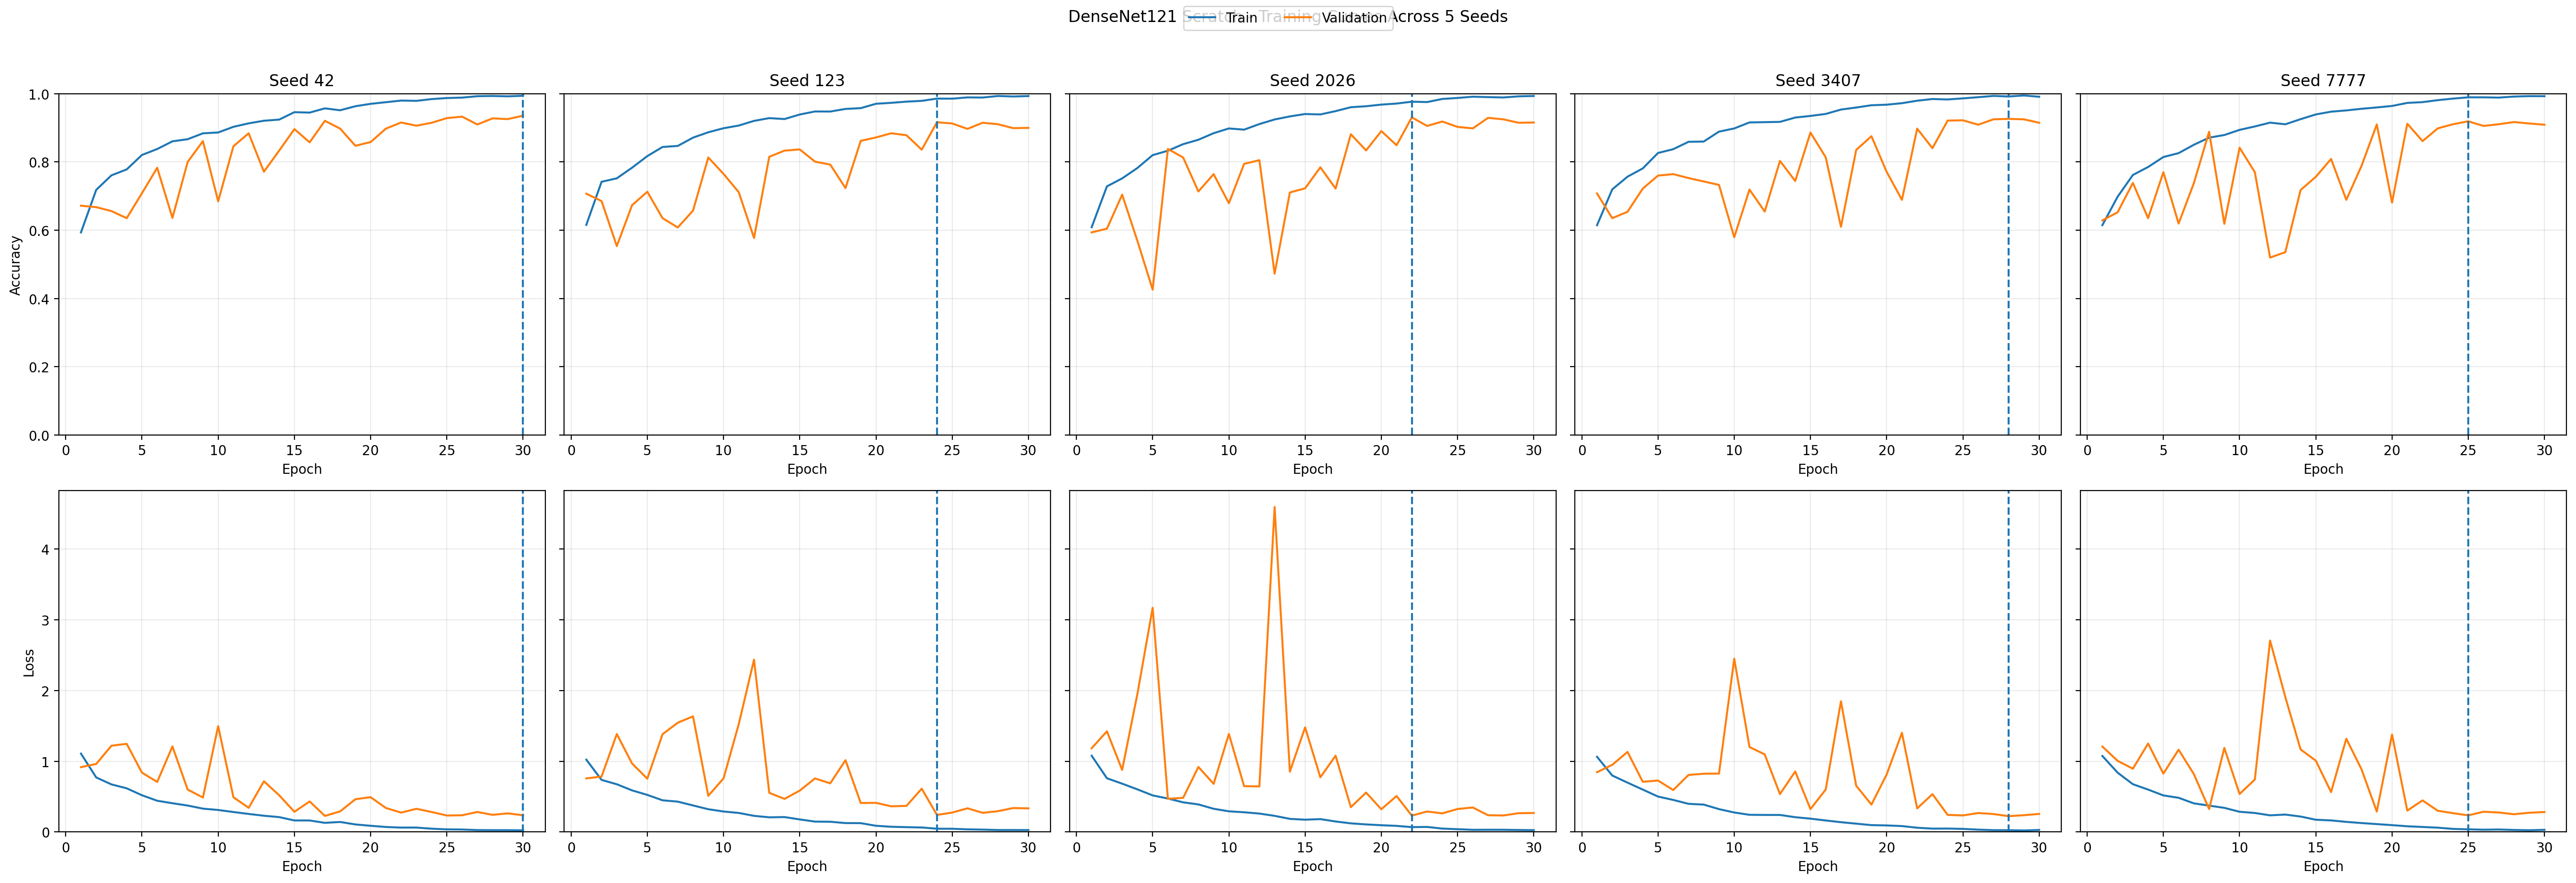

In [17]:

# ============================================================
# 14B. PAPER-STYLE 5-SEED VALIDATION PANELS
# ============================================================

# ------------------------------------------------------------
# A. Training curves: 2 rows x 5 seed columns
#    Row 1 = Accuracy, Row 2 = Loss
# ------------------------------------------------------------

histories = {}
for seed in SEEDS:
    history_path = OUT_DIR / f"seed_{seed}" / "logs" / "history.csv"
    histories[seed] = pd.read_csv(history_path)

fig, axes = plt.subplots(
    2,
    len(SEEDS),
    figsize=(27, 9),
    sharey="row"
)

all_losses = []
for seed in SEEDS:
    all_losses.extend(histories[seed]["loss"].tolist())
    all_losses.extend(histories[seed]["val_loss"].tolist())

loss_upper = max(all_losses) * 1.05

for col, seed in enumerate(SEEDS):
    hist = histories[seed]
    best_epoch = int(hist.sort_values(
        ["val_macro_f1", "val_loss", "epoch"], ascending=[False, True, True]
    ).iloc[0]["epoch"])

    axes[0, col].plot(hist["epoch"], hist["accuracy"], label="Train")
    axes[0, col].plot(hist["epoch"], hist["val_accuracy"], label="Validation")
    axes[0, col].axvline(best_epoch, linestyle="--")
    axes[0, col].set_title(f"Seed {seed}")
    axes[0, col].set_xlabel("Epoch")
    axes[0, col].set_ylim(0, 1)
    axes[0, col].grid(alpha=0.25)

    axes[1, col].plot(hist["epoch"], hist["loss"], label="Train")
    axes[1, col].plot(hist["epoch"], hist["val_loss"], label="Validation")
    axes[1, col].axvline(best_epoch, linestyle="--")
    axes[1, col].set_xlabel("Epoch")
    axes[1, col].set_ylim(0, loss_upper)
    axes[1, col].grid(alpha=0.25)

axes[0, 0].set_ylabel("Accuracy")
axes[1, 0].set_ylabel("Loss")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.suptitle(
    "DenseNet121 Scratch - Training Curves Across 5 Seeds",
    y=1.02
)
fig.tight_layout()

training_panel_path = PANEL_DIR / "training_curves_5seeds_panel.png"
fig.savefig(training_panel_path, dpi=200, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------
# B. Normalized Validation confusion matrices: 1 x 5
# ------------------------------------------------------------

fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5))

for col, seed in enumerate(SEEDS):
    cm_path = (
        OUT_DIR / f"seed_{seed}" / "validation" /
        "confusion_matrix_normalized.csv"
    )
    cm = pd.read_csv(cm_path, index_col=0).to_numpy()
    axes[col].imshow(cm, vmin=0, vmax=1, aspect="auto")
    axes[col].set_title(f"Seed {seed}")
    axes[col].set_xticks(range(NUM_CLASSES))
    axes[col].set_yticks(range(NUM_CLASSES))
    axes[col].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    if col == 0:
        axes[col].set_yticklabels(CLASS_NAMES)
        axes[col].set_ylabel("True label")
    else:
        axes[col].set_yticklabels([])
    axes[col].set_xlabel("Predicted label")

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            axes[col].text(
                j, i, f"{cm[i, j]:.2f}",
                ha="center", va="center", fontsize=8
            )

fig.suptitle(
    "DenseNet121 Scratch - Validation Normalized Confusion Matrices Across 5 Seeds",
    y=1.03
)
fig.tight_layout()
validation_panel_path = PANEL_DIR / "validation_confusion_matrices_5seeds_panel.png"
fig.savefig(validation_panel_path, dpi=200, bbox_inches="tight")
plt.close(fig)

print("Created:", training_panel_path)
print("Created:", validation_panel_path)
display(Image.open(training_panel_path))



# FINAL TEST GATE

**Dừng ở đây nếu bạn chưa muốn mở Test Set.**

Sau khi 5 seeds đã train xong và bạn xác nhận cấu hình không thay đổi nữa:

1. quay lại Cell `03. CONFIGURATION`;
2. đổi:

```python
RUN_FINAL_TEST = True
```

3. set `RUN_TRAINING = False`;
4. restart the session and run setup through the Validation summaries;
5. run from cell `15. FINAL TEST` downward. The training cell loads saved summaries and never retrains.

Final Test sẽ build lại đúng architecture cho từng seed, load the Validation-macro-F1 checkpoint, rồi đánh giá cùng một Test Set đã khóa.


In [18]:

# ============================================================
# 15. FINAL TEST - 5 SEEDS
# ============================================================

test_result_rows = []

if not RUN_FINAL_TEST:

    print(
        "FINAL TEST IS LOCKED.\n"
        "RUN_FINAL_TEST = False\n"
        "Không đánh giá Test trong lần chạy này."
    )

else:

    test_ds = make_dataset(
        test_paths,
        test_labels,
        seed=SEEDS[0],
        training=False
    )

    for run_index, seed in enumerate(SEEDS, start=1):

        print("\n" + "=" * 80)
        print(
            f"FINAL TEST {run_index}/{len(SEEDS)} - SEED {seed}"
        )
        print("=" * 80)

        tf.keras.backend.clear_session()
        gc.collect()
        set_global_seed(seed)

        seed_dir = OUT_DIR / f"seed_{seed}"

        best_weights_path = (
            seed_dir /
            "checkpoints" /
            f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5"
        )

        if not best_weights_path.exists():
            raise FileNotFoundError(
                f"Missing checkpoint: {best_weights_path}"
            )

        metric_dir = seed_dir / "test_metrics"
        figure_dir = seed_dir / "test_figures"
        prediction_dir = seed_dir / "test_predictions"
        error_dir = prediction_dir / "error_cases"

        for folder in [
            metric_dir,
            figure_dir,
            prediction_dir,
            error_dir,
        ]:
            folder.mkdir(
                parents=True,
                exist_ok=True
            )

        # ----------------------------------------------------
        # Rebuild exact architecture and load best weights
        # ----------------------------------------------------

        with strategy.scope():

            model = build_densenet121_model(seed)

            # Load weights BEFORE compile so Final Test does not
            # attempt to restore stale optimizer variables.
            model.load_weights(
                best_weights_path
            )

            model.compile(
                optimizer=tf.keras.optimizers.Adam(
                    learning_rate=INITIAL_LR
                ),
                loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                metrics=["accuracy"],
            )

        # ----------------------------------------------------
        # Evaluate
        # ----------------------------------------------------

        test_loss, test_accuracy_keras = model.evaluate(
            test_ds,
            verbose=0
        )

        # Warm-up bằng nguyên batch đầu tiên.
        # Không dùng batch=1 khi MirroredStrategy có nhiều GPU.
        _ = model.predict(
            test_ds.take(1),
            verbose=0
        )

        prediction_start = time.perf_counter()

        # Predict toàn bộ Test Dataset trong một call để giảm overhead
        # và cho phép MirroredStrategy tự phân phối batch ổn định.
        y_prob = model.predict(
            test_ds,
            verbose=0
        )

        prediction_time = (
            time.perf_counter() -
            prediction_start
        )

        # Test dataset không shuffle nên thứ tự prediction
        # trùng với test_labels.
        y_true = np.asarray(
            test_labels,
            dtype=np.int32
        )

        y_pred = np.argmax(
            y_prob,
            axis=1
        )

        confidences = np.max(
            y_prob,
            axis=1
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        macro_precision = precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        balanced_acc = balanced_accuracy_score(
            y_true,
            y_pred
        )

        weighted_precision = precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        weighted_recall = recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        inference_ms = (
            prediction_time /
            len(y_true)
        ) * 1000.0

        fps = (
            len(y_true) /
            prediction_time
        )

        # ----------------------------------------------------
        # Reports
        # ----------------------------------------------------

        report_df = pd.DataFrame(
            classification_report(
                y_true,
                y_pred,
                target_names=CLASS_NAMES,
                output_dict=True,
                zero_division=0,
            )
        ).transpose()

        report_df.to_csv(
            metric_dir /
            "classification_report.csv"
        )

        cm = confusion_matrix(
            y_true,
            y_pred
        )

        cm_norm = confusion_matrix(
            y_true,
            y_pred,
            normalize="true"
        )

        pd.DataFrame(
            cm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        ).to_csv(
            metric_dir /
            "confusion_matrix.csv"
        )

        pd.DataFrame(
            cm_norm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        ).to_csv(
            metric_dir /
            "confusion_matrix_normalized.csv"
        )

        # ----------------------------------------------------
        # Confusion matrix figures
        # ----------------------------------------------------

        fig, ax = plt.subplots(figsize=(8, 7))

        matrix_display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=CLASS_NAMES
        ).plot(
            ax=ax,
            cmap=MATRIX_CMAP,
            values_format="d",
            colorbar=False
        )
        for label in matrix_display.text_.ravel():
            label.set_color("black")

        plt.title(
            f"Test Confusion Matrix - Seed {seed}"
        )

        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()

        plt.savefig(
            figure_dir /
            "confusion_matrix.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.close()

        fig, ax = plt.subplots(figsize=(8, 7))

        matrix_display = ConfusionMatrixDisplay(
            confusion_matrix=cm_norm,
            display_labels=CLASS_NAMES
        ).plot(
            ax=ax,
            cmap=MATRIX_CMAP,
            values_format=".2f",
            colorbar=False
        )
        for label in matrix_display.text_.ravel():
            label.set_color("black")

        plt.title(
            f"Normalized Test Confusion Matrix - Seed {seed}"
        )

        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()

        plt.savefig(
            figure_dir /
            "confusion_matrix_normalized.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.close()

        # ----------------------------------------------------
        # Prediction CSV
        # ----------------------------------------------------

        predictions_df = pd.DataFrame({
            "filename": test_meta["path"],
            "true_label": [
                CLASS_NAMES[int(i)]
                for i in y_true
            ],
            "predicted_label": [
                CLASS_NAMES[int(i)]
                for i in y_pred
            ],
            "confidence": confidences,
            "correct": y_true == y_pred,
        })

        predictions_df.to_csv(
            prediction_dir /
            "predictions.csv",
            index=False
        )

        wrong_df = (
            predictions_df[
                ~predictions_df["correct"]
            ]
            .sort_values(
                "confidence",
                ascending=False
            )
        )

        wrong_df.head(20).to_csv(
            error_dir /
            "highest_confidence_wrong.csv",
            index=False
        )

        correct_low_conf = (
            predictions_df[
                predictions_df["correct"]
            ]
            .sort_values(
                "confidence",
                ascending=True
            )
        )

        correct_low_conf.head(20).to_csv(
            error_dir /
            "lowest_confidence_correct.csv",
            index=False
        )

        # ----------------------------------------------------
        # Seed metrics
        # ----------------------------------------------------

        seed_metrics = {
            "seed": seed,
            "test_loss": float(test_loss),
            "accuracy": float(accuracy),
            "macro_precision": float(macro_precision),
            "macro_recall": float(macro_recall),
            "macro_f1": float(macro_f1),
            "balanced_accuracy": float(balanced_acc),
            "weighted_precision": float(weighted_precision),
            "weighted_recall": float(weighted_recall),
            "weighted_f1": float(weighted_f1),
            "weights_size_mb": float(
                best_weights_path.stat().st_size /
                (1024 ** 2)
            ),
            "inference_time_ms_per_image": float(inference_ms),
            "fps": float(fps),
        }

        (
            metric_dir /
            "metrics.json"
        ).write_text(
            json.dumps(
                seed_metrics,
                indent=2
            ),
            encoding="utf-8"
        )

        test_result_rows.append(
            seed_metrics
        )

        print(json.dumps(seed_metrics, indent=2))

        del model
        tf.keras.backend.clear_session()
        gc.collect()


    test_results_df = pd.DataFrame(
        test_result_rows
    )

    test_results_df.to_csv(
        AGGREGATE_DIR /
        "aggregate_test_results.csv",
        index=False
    )

    display(test_results_df)


FINAL TEST IS LOCKED.
RUN_FINAL_TEST = False
Không đánh giá Test trong lần chạy này.


In [19]:

# ============================================================
# 16. TEST MEAN ± STD + THESIS TABLE
# ============================================================

if not RUN_FINAL_TEST:

    print(
        "Skipped: Final Test chưa chạy."
    )

else:

    summary_metrics = [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "balanced_accuracy",
        "weighted_f1",
        "inference_time_ms_per_image",
        "fps",
    ]

    summary_rows = []

    for metric in summary_metrics:

        values = test_results_df[metric]

        summary_rows.append({
            "metric": metric,
            "mean": float(values.mean()),
            "std": float(values.std(ddof=1)),
            "report": (
                f"{values.mean():.6f} ± "
                f"{values.std(ddof=1):.6f}"
            ),
        })

    mean_std_df = pd.DataFrame(
        summary_rows
    )

    display(mean_std_df)

    mean_std_df.to_csv(
        AGGREGATE_DIR /
        "test_mean_std_summary.csv",
        index=False
    )

    thesis_metrics = [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "balanced_accuracy",
        "weighted_f1",
    ]

    thesis_rows = []

    for metric in thesis_metrics:

        values = (
            test_results_df[metric]
            * 100
        )

        thesis_rows.append({
            "Metric": metric,
            "Mean (%)": float(values.mean()),
            "Std (%)": float(values.std(ddof=1)),
            "Report": (
                f"{values.mean():.2f} ± "
                f"{values.std(ddof=1):.2f}%"
            ),
        })

    thesis_summary_df = pd.DataFrame(
        thesis_rows
    )

    print("\nThesis-ready table:")
    display(thesis_summary_df)

    thesis_summary_df.to_csv(
        AGGREGATE_DIR /
        "thesis_test_mean_std_summary.csv",
        index=False
    )

    aggregate_metrics = {
        "experiment_id": EXPERIMENT_ID,
        "model": MODEL_NAME,
        "training_mode": TRAINING_MODE,
        "dataset": DATASET_VERSION,
        "seeds": SEEDS,
        "num_seeds": len(SEEDS),
        "std_definition": "sample standard deviation (ddof=1)",
        "test_set_locked": True,
        "per_seed_results": test_result_rows,
        "summary": {
            row["metric"]: {
                "mean": float(row["mean"]),
                "std": float(row["std"]),
            }
            for row in summary_rows
        },
    }

    (
        AGGREGATE_DIR /
        "aggregate_test_metrics.json"
    ).write_text(
        json.dumps(
            aggregate_metrics,
            indent=2
        ),
        encoding="utf-8"
    )


Skipped: Final Test chưa chạy.


In [20]:

# ============================================================
# 17. PER-CLASS MEAN ± STD ACROSS 5 SEEDS
# ============================================================

if not RUN_FINAL_TEST:

    print(
        "Skipped: Final Test chưa chạy."
    )

else:

    per_class_rows = []

    for class_name in CLASS_NAMES:

        precision_values = []
        recall_values = []
        f1_values = []

        for seed in SEEDS:

            report_path = (
                OUT_DIR /
                f"seed_{seed}" /
                "test_metrics" /
                "classification_report.csv"
            )

            report_df = pd.read_csv(
                report_path,
                index_col=0
            )

            precision_values.append(
                float(
                    report_df.loc[
                        class_name,
                        "precision"
                    ]
                )
            )

            recall_values.append(
                float(
                    report_df.loc[
                        class_name,
                        "recall"
                    ]
                )
            )

            f1_values.append(
                float(
                    report_df.loc[
                        class_name,
                        "f1-score"
                    ]
                )
            )

        per_class_rows.append({
            "class": class_name,
            "precision_mean": np.mean(precision_values),
            "precision_std": np.std(precision_values, ddof=1),
            "recall_mean": np.mean(recall_values),
            "recall_std": np.std(recall_values, ddof=1),
            "f1_mean": np.mean(f1_values),
            "f1_std": np.std(f1_values, ddof=1),
            "f1_report": (
                f"{np.mean(f1_values)*100:.2f} ± "
                f"{np.std(f1_values, ddof=1)*100:.2f}%"
            ),
        })

    per_class_summary_df = pd.DataFrame(
        per_class_rows
    )

    display(per_class_summary_df)

    per_class_summary_df.to_csv(
        AGGREGATE_DIR /
        "per_class_test_mean_std.csv",
        index=False
    )


Skipped: Final Test chưa chạy.


In [21]:
# ============================================================
# 17B. PAPER-STYLE TEST CONFUSION MATRIX PANELS
# ============================================================

if not RUN_FINAL_TEST:

    print("Skipped: Final Test chưa chạy.")

else:

    # ========================================================
    # 1. LOAD ALL CONFUSION MATRICES
    # ========================================================

    raw_cms = {}
    normalized_cms = {}

    for seed in SEEDS:

        raw_path = (
            OUT_DIR /
            f"seed_{seed}" /
            "test_metrics" /
            "confusion_matrix.csv"
        )

        normalized_path = (
            OUT_DIR /
            f"seed_{seed}" /
            "test_metrics" /
            "confusion_matrix_normalized.csv"
        )

        raw_cms[seed] = (
            pd.read_csv(
                raw_path,
                index_col=0
            )
            .to_numpy()
        )

        normalized_cms[seed] = (
            pd.read_csv(
                normalized_path,
                index_col=0
            )
            .to_numpy()
        )


    # ========================================================
    # 2. RAW CONFUSION MATRICES - 5 SEEDS SIDE BY SIDE
    # ========================================================

    raw_vmax = max(
        np.max(raw_cms[seed])
        for seed in SEEDS
    )

    fig, axes = plt.subplots(
        1,
        len(SEEDS),
        figsize=(30, 6.5),
        constrained_layout=True
    )

    last_im = None

    for col, seed in enumerate(SEEDS):

        cm = raw_cms[seed]
        ax = axes[col]

        last_im = ax.imshow(
            cm,
            cmap=MATRIX_CMAP,
            vmin=0,
            vmax=raw_vmax,
            aspect="equal"
        )

        ax.set_title(
            f"Seed {seed}",
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        ax.set_xticks(
            range(NUM_CLASSES)
        )

        ax.set_yticks(
            range(NUM_CLASSES)
        )

        ax.set_xticklabels(
            CLASS_NAMES,
            rotation=40,
            ha="right",
            fontsize=9
        )

        if col == 0:

            ax.set_yticklabels(
                CLASS_NAMES,
                fontsize=9
            )

            ax.set_ylabel(
                "True label",
                fontsize=11
            )

        else:

            ax.set_yticklabels([])

        ax.set_xlabel(
            "Predicted label",
            fontsize=10
        )

        # ----------------------------------------------------
        # Cell values
        # ----------------------------------------------------

        for i in range(NUM_CLASSES):

            for j in range(NUM_CLASSES):

                value = int(
                    cm[i, j]
                )

                ax.text(
                    j,
                    i,
                    f"{value}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="black"
                )

        # Remove outer frame
        for spine in ax.spines.values():
            spine.set_visible(False)


    # --------------------------------------------------------
    # Shared colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        last_im,
        ax=axes,
        fraction=0.018,
        pad=0.015
    )

    cbar.set_label(
        "Number of images",
        fontsize=10
    )

    fig.suptitle(
        (
            "DenseNet121 Scratch - "
            "Test Confusion Matrices Across 5 Seeds"
        ),
        fontsize=16,
        fontweight="bold"
    )

    raw_panel = (
        PANEL_DIR /
        "test_confusion_matrices_5seeds_panel.png"
    )

    fig.savefig(
        raw_panel,
        dpi=220,
        bbox_inches="tight"
    )

    plt.close(fig)


    # ========================================================
    # 3. NORMALIZED CONFUSION MATRICES
    # ========================================================

    fig, axes = plt.subplots(
        1,
        len(SEEDS),
        figsize=(30, 6.5),
        constrained_layout=True
    )

    last_im = None

    for col, seed in enumerate(SEEDS):

        cm = normalized_cms[seed]
        ax = axes[col]

        last_im = ax.imshow(
            cm,
            cmap=MATRIX_CMAP,
            vmin=0.0,
            vmax=1.0,
            aspect="equal"
        )

        ax.set_title(
            f"Seed {seed}",
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        ax.set_xticks(
            range(NUM_CLASSES)
        )

        ax.set_yticks(
            range(NUM_CLASSES)
        )

        ax.set_xticklabels(
            CLASS_NAMES,
            rotation=40,
            ha="right",
            fontsize=9
        )

        if col == 0:

            ax.set_yticklabels(
                CLASS_NAMES,
                fontsize=9
            )

            ax.set_ylabel(
                "True label",
                fontsize=11
            )

        else:

            ax.set_yticklabels([])

        ax.set_xlabel(
            "Predicted label",
            fontsize=10
        )

        # ----------------------------------------------------
        # Cell values
        # ----------------------------------------------------

        for i in range(NUM_CLASSES):

            for j in range(NUM_CLASSES):

                value = float(
                    cm[i, j]
                )

                ax.text(
                    j,
                    i,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="black"
                )

        # Remove outer frame
        for spine in ax.spines.values():
            spine.set_visible(False)


    # --------------------------------------------------------
    # Shared colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        last_im,
        ax=axes,
        fraction=0.018,
        pad=0.015
    )

    cbar.set_label(
        "Row-normalized proportion",
        fontsize=10
    )

    fig.suptitle(
        (
            "DenseNet121 Scratch - "
            "Normalized Test Confusion Matrices Across 5 Seeds"
        ),
        fontsize=16,
        fontweight="bold"
    )

    normalized_panel = (
        PANEL_DIR /
        "test_confusion_matrices_normalized_5seeds_panel.png"
    )

    fig.savefig(
        normalized_panel,
        dpi=220,
        bbox_inches="tight"
    )

    plt.close(fig)


    # ========================================================
    # 4. OUTPUT
    # ========================================================

    print(
        "Created:",
        raw_panel
    )

    print(
        "Created:",
        normalized_panel
    )

    display(
        Image.open(
            normalized_panel
        )
    )


    # ========================================================
    # 5. UPDATE EXPERIMENT METADATA
    # ========================================================

    _cfg = json.loads(
        config_path.read_text(
            encoding="utf-8"
        )
    )

    _cfg.setdefault(
        "test_protocol",
        {}
    )

    _cfg[
        "test_protocol"
    ][
        "run_final_test"
    ] = True

    _cfg[
        "test_protocol"
    ][
        "final_test_completed"
    ] = True

    config_path.write_text(
        json.dumps(
            _cfg,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    print(
        "Updated experiment_config.json: "
        "final_test_completed = True"
    )

Skipped: Final Test chưa chạy.



# Deployment package for later YOLO integration

Để FULL archive có thể dùng lại sau này, notebook export một model deployment **chỉ dựa trên Validation**.

Seed deployment được chọn bằng:

```text
highest Validation Macro-F1
→ tie-break: lower Validation Loss
```

Test không tham gia lựa chọn seed deployment.

Archive sẽ có:

```text
model_package/
├── deployment_model.keras
├── densenet121_feature_extractor.keras
├── densenet121_embedding_model.keras
├── deployment_metadata.json
└── label_map.json
```

- `deployment_model.keras`: dùng trực tiếp cho pipeline `YOLO crop → DenseNet classifier`.
- `densenet121_feature_extractor.keras`: feature map trước Global Average Pooling.
- `densenet121_embedding_model.keras`: vector embedding sau Global Average Pooling, hữu ích nếu sau này cần feature fusion.


In [22]:

# ============================================================
# 18. EXPORT DEPLOYMENT MODEL PACKAGE - VALIDATION ONLY
# ============================================================

if "validation_results_df" not in globals():
    validation_results_df = pd.read_csv(
        AGGREGATE_DIR / "validation_results_5seeds.csv"
    )

ranked = validation_results_df.sort_values(
    ["val_macro_f1", "val_loss", "seed"],
    ascending=[False, True, True]
).reset_index(drop=True)

deployment_seed = int(ranked.loc[0, "seed"])
DEMO_SEED = deployment_seed

print("Deployment seed selected by Validation only:", deployment_seed)

deployment_weights_path = (
    OUT_DIR / f"seed_{deployment_seed}" / "checkpoints" /
    f"DENSENET121_SCRATCH_seed_{deployment_seed}_best.weights.h5"
)

if not deployment_weights_path.exists():
    raise FileNotFoundError(deployment_weights_path)

tf.keras.backend.clear_session()
gc.collect()

with strategy.scope():
    deployment_model = build_densenet121_model(deployment_seed)
    deployment_model.load_weights(deployment_weights_path)

# Fresh uncompiled model -> portable .keras without relying on old optimizer state.
deployment_model_path = MODEL_PACKAGE_DIR / "deployment_model.keras"
deployment_model.save(deployment_model_path)

# ------------------------------------------------------------
# Standalone DenseNet feature extractor for downstream YOLO.
# Rebuild inference-only preprocessing + backbone and copy the
# trained DenseNet121 weights from the deployment classifier.
# ------------------------------------------------------------

trained_backbone = deployment_model.get_layer("densenet121")

feature_inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

feature_x = layers.Rescaling(
    1.0 / 255.0,
    name="rescale_0_1"
)(feature_inputs)

feature_backbone = tf.keras.applications.DenseNet121(
    include_top=False,
    weights=None,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
for layer in feature_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.momentum = 0.90
feature_backbone.set_weights(
    trained_backbone.get_weights()
)

feature_outputs = feature_backbone(
    feature_x,
    training=False
)

feature_extractor = keras.Model(
    inputs=feature_inputs,
    outputs=feature_outputs,
    name="DenseNet121_feature_extractor"
)
feature_extractor_path = MODEL_PACKAGE_DIR / "densenet121_feature_extractor.keras"
feature_extractor.save(feature_extractor_path)

embedding_outputs = layers.GlobalAveragePooling2D(
    name="embedding_global_average_pooling"
)(feature_outputs)

embedding_model = keras.Model(
    inputs=feature_inputs,
    outputs=embedding_outputs,
    name="DenseNet121_embedding_model"
)
embedding_model_path = MODEL_PACKAGE_DIR / "densenet121_embedding_model.keras"
embedding_model.save(embedding_model_path)

label_map = {str(i): name for i, name in enumerate(CLASS_NAMES)}
(MODEL_PACKAGE_DIR / "label_map.json").write_text(
    json.dumps(label_map, indent=2), encoding="utf-8"
)

deployment_metadata = {
    "experiment_id": EXPERIMENT_ID,
    "model": MODEL_NAME,
    "training_mode": TRAINING_MODE,
    "deployment_seed": deployment_seed,
    "selection_source": "validation only",
    "selection_metric": "val_macro_f1",
    "tie_break": "lower val_loss, then lower seed for deployment determinism",
    "test_used_for_selection": False,
    "input_size": [IMG_SIZE, IMG_SIZE, 3],
    "class_names": CLASS_NAMES,
    "contains_rescaling_layer": True,
    "external_divide_by_255": False,
    "deployment_model": "deployment_model.keras",
    "feature_extractor": "densenet121_feature_extractor.keras",
    "embedding_model": "densenet121_embedding_model.keras",
    "embedding_dimension": 1024,
    "intended_downstream_use": "YOLO crop classification or feature fusion",
    "source_weights": str(deployment_weights_path),
}
(MODEL_PACKAGE_DIR / "deployment_metadata.json").write_text(
    json.dumps(deployment_metadata, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Saved deployment model :", deployment_model_path)
print("Saved feature extractor:", feature_extractor_path)
print("Saved embedding model  :", embedding_model_path)


Deployment seed selected by Validation only: 42
Global seed set to: 42
Saved deployment model : /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008/model_package/deployment_model.keras
Saved feature extractor: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008/model_package/densenet121_feature_extractor.keras
Saved embedding model  : /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008/model_package/densenet121_embedding_model.keras


In [23]:

# ============================================================
# 19. EXPORT REUSABLE CODE FOR FUTURE YOLO / CONTINUE TRAINING
# ============================================================

model_builder_code = r"""
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


def build_data_augmentation(seed):
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed + 1),
        layers.RandomRotation(0.04, seed=seed + 2),
        layers.RandomZoom(
            height_factor=(-0.05, 0.05),
            width_factor=(-0.05, 0.05),
            seed=seed + 3,
        ),
        layers.RandomTranslation(0.03, 0.03, seed=seed + 4),
        layers.RandomContrast(0.08, seed=seed + 5),
    ], name=f"data_augmentation_seed_{seed}")


def build_densenet121_model(seed, img_size=224, num_classes=5, head_units=512, head_dropout=0.40):
    keras.utils.set_random_seed(seed)
    inputs = keras.Input(shape=(img_size, img_size, 3), name="image")
    x = build_data_augmentation(seed)(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)
    backbone = tf.keras.applications.DenseNet121(
        include_top=False,
        weights=None,
        input_shape=(img_size, img_size, 3),
    )
    backbone.trainable = True
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.momentum = 0.90
    x = backbone(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dense(head_units, activation="relu", name="classifier_dense")(x)
    x = layers.BatchNormalization(momentum=0.90, name="classifier_bn")(x)
    x = layers.Dropout(head_dropout, seed=seed + 6, name="classifier_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=f"DenseNet121_Scratch_seed_{seed}")
"""

(CODE_PACKAGE_DIR / "densenet121_model_builder.py").write_text(
    model_builder_code, encoding="utf-8"
)

yolo_adapter_code = r"""
# YOLO detection -> DenseNet121 crop classifier example.
# deployment_model.keras already contains Rescaling(1/255),
# so do NOT divide the crop by 255 outside the model.

from pathlib import Path
import json
import numpy as np
from PIL import Image
from tensorflow import keras

MODEL_DIR = Path("model_package")
classifier = keras.models.load_model(MODEL_DIR / "deployment_model.keras", compile=False)
label_map = json.loads((MODEL_DIR / "label_map.json").read_text())


def classify_crop(crop, img_size=224):
    if isinstance(crop, np.ndarray):
        crop = Image.fromarray(crop.astype(np.uint8))
    crop = crop.convert("RGB").resize((img_size, img_size))
    x = np.asarray(crop, dtype=np.float32)[None, ...]
    probs = classifier.predict(x, verbose=0)[0]
    pred_id = int(np.argmax(probs))
    return {
        "class_id": pred_id,
        "class_name": label_map[str(pred_id)],
        "confidence": float(probs[pred_id]),
        "probabilities": probs.tolist(),
    }
"""
(CODE_PACKAGE_DIR / "yolo_classifier_adapter.py").write_text(
    yolo_adapter_code, encoding="utf-8"
)

continue_training_code = r"""
from tensorflow import keras

model = keras.models.load_model(
    "model_package/deployment_model.keras",
    compile=False,
)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Continue with your train_ds / val_ds:
# model.fit(train_ds, validation_data=val_ds, ...)
"""
(CODE_PACKAGE_DIR / "continue_training_example.py").write_text(
    continue_training_code, encoding="utf-8"
)

print("Reusable code package:")
for p in sorted(CODE_PACKAGE_DIR.iterdir()):
    print("-", p.name)


Reusable code package:
- continue_training_example.py
- densenet121_model_builder.py
- yolo_classifier_adapter.py



# Manual image inference

Manual demo dùng `deployment_model.keras`, tức seed được chọn bằng **Validation only**.

Model đã chứa `Rescaling(1/255)`, vì vậy không chia ảnh cho 255 ở ngoài model.


In [24]:
# ============================================================
# 20. MANUAL UPLOAD INFERENCE
#     SAFE FOR SINGLE IMAGE + MIRRORED STRATEGY
# ============================================================

# ------------------------------------------------------------
# Load deployment model if needed
# ------------------------------------------------------------

if "deployment_model" not in globals():

    deployment_model = keras.models.load_model(
        MODEL_PACKAGE_DIR /
        "deployment_model.keras",
        compile=False
    )

print(
    "Deployment model ready."
)

print(
    "Number of replicas:",
    strategy.num_replicas_in_sync
)


# ============================================================
# PREDICTION FUNCTION
# ============================================================

def predict_uploaded_image(
    model,
    image_bytes,
    filename
):

    # --------------------------------------------------------
    # 1. Read uploaded image
    # --------------------------------------------------------

    img = Image.open(
        io.BytesIO(
            image_bytes
        )
    ).convert(
        "RGB"
    )

    # --------------------------------------------------------
    # 2. Resize
    # --------------------------------------------------------

    img_resized = img.resize(
        (
            IMG_SIZE,
            IMG_SIZE
        )
    )

    img_array = np.asarray(
        img_resized,
        dtype=np.float32
    )

    # Original single sample
    single_batch = np.expand_dims(
        img_array,
        axis=0
    )

    # --------------------------------------------------------
    # 3. IMPORTANT:
    # MirroredStrategy cannot safely predict batch=1
    # when using multiple GPUs.
    #
    # Repeat the SAME image so each GPU receives >= 1 sample.
    # --------------------------------------------------------

    num_replicas = max(
        1,
        int(
            strategy.num_replicas_in_sync
        )
    )

    inference_batch = np.repeat(
        single_batch,
        repeats=num_replicas,
        axis=0
    )

    print(
        "Input batch shape:",
        inference_batch.shape
    )

    # Example T4 x2:
    # (2, 224, 224, 3)
    #
    # GPU 0 -> 1 image
    # GPU 1 -> 1 image

    # --------------------------------------------------------
    # 4. Predict
    # --------------------------------------------------------

    all_probs = model.predict(
        inference_batch,
        verbose=0
    )

    # Every repeated sample is identical.
    # Only use prediction of the first one.
    probs = all_probs[0]

    # --------------------------------------------------------
    # 5. Decode prediction
    # --------------------------------------------------------

    pred_idx = int(
        np.argmax(
            probs
        )
    )

    confidence = float(
        probs[
            pred_idx
        ]
    )

    # --------------------------------------------------------
    # 6. Result table
    # --------------------------------------------------------

    result_df = pd.DataFrame({
        "Class": CLASS_NAMES,
        "Probability": probs,
        "Probability (%)": (
            probs * 100
        ),
    }).sort_values(
        "Probability",
        ascending=False
    ).reset_index(
        drop=True
    )

    # --------------------------------------------------------
    # 7. Display result
    # --------------------------------------------------------

    print(
        "=" * 65
    )

    print(
        "Image           :",
        filename
    )

    print(
        "Prediction      :",
        CLASS_NAMES[
            pred_idx
        ]
    )

    print(
        f"Confidence      : "
        f"{confidence * 100:.2f}%"
    )

    print(
        "Deployment seed :",
        DEMO_SEED
    )

    print(
        "GPU replicas    :",
        num_replicas
    )

    print(
        "=" * 65
    )

    display(
        result_df
    )

    # --------------------------------------------------------
    # 8. Show image
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 7)
    )

    plt.imshow(
        img
    )

    plt.title(
        (
            f"Prediction: "
            f"{CLASS_NAMES[pred_idx]}\n"
            f"Confidence: "
            f"{confidence * 100:.2f}%"
        )
    )

    plt.axis(
        "off"
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# FILE UPLOAD WIDGET
# ============================================================

uploader = widgets.FileUpload(
    accept=(
        ".jpg,.jpeg,.png,.webp"
    ),
    multiple=False,
    description="Upload Image"
)

predict_button = widgets.Button(
    description="Predict",
    button_style="success",
    icon="check"
)

output = widgets.Output()

display(
    uploader
)

display(
    predict_button
)

display(
    output
)


# ============================================================
# READ UPLOADED FILE
# Compatible with ipywidgets 7 and 8
# ============================================================

def get_uploaded_file(
    upload_widget
):

    value = (
        upload_widget.value
    )

    if not value:
        return None, None

    # --------------------------------------------------------
    # ipywidgets 8
    # --------------------------------------------------------

    if isinstance(
        value,
        (tuple, list)
    ):

        uploaded_file = (
            value[0]
        )

        filename = (
            uploaded_file[
                "name"
            ]
        )

        content = (
            uploaded_file[
                "content"
            ]
        )

        if hasattr(
            content,
            "tobytes"
        ):
            content = (
                content.tobytes()
            )

        return (
            filename,
            content
        )

    # --------------------------------------------------------
    # ipywidgets 7
    # --------------------------------------------------------

    if isinstance(
        value,
        dict
    ):

        filename = list(
            value.keys()
        )[0]

        uploaded_file = (
            value[
                filename
            ]
        )

        content = (
            uploaded_file[
                "content"
            ]
        )

        if hasattr(
            content,
            "tobytes"
        ):
            content = (
                content.tobytes()
            )

        return (
            filename,
            content
        )

    return None, None


# ============================================================
# BUTTON CALLBACK
# ============================================================

def on_predict_clicked(_):

    with output:

        output.clear_output()

        filename, image_bytes = (
            get_uploaded_file(
                uploader
            )
        )

        if image_bytes is None:

            print(
                "Vui lòng upload ảnh trước."
            )

            return

        try:

            predict_uploaded_image(
                deployment_model,
                image_bytes,
                filename
            )

        except Exception as e:

            print(
                "Prediction error:"
            )

            print(
                type(e).__name__,
                ":",
                e
            )


predict_button.on_click(
    on_predict_clicked
)

print(
    "Upload một ảnh rồi bấm Predict."
)

Deployment model ready.
Number of replicas: 1


FileUpload(value={}, accept='.jpg,.jpeg,.png,.webp', description='Upload Image')

Button(button_style='success', description='Predict', icon='check', style=ButtonStyle())

Output()

Upload một ảnh rồi bấm Predict.


## External holdout results — after freezing Validation and internal Test


In [25]:
# External evaluation is separate from the internal V05 Test driver above.
def make_real_holdout_dataset(holdout_manifest):
    dataset = tf.data.Dataset.from_tensor_slices((
        holdout_manifest["path"].tolist(),
        holdout_manifest["label"].to_numpy(dtype=np.int32),
    ))
    return dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
        BATCH_SIZE, drop_remainder=False
    ).prefetch(tf.data.AUTOTUNE)  # No shuffle or augmentation; same input decoding.


def load_real_holdout_model(seed):
    with strategy.scope():
        holdout_model = build_densenet121_model(seed)
        holdout_model.load_weights(holdout_checkpoints[seed])
    return holdout_model


def clear_real_holdout_session():
    tf.keras.backend.clear_session()
    gc.collect()


if RUN_FINAL_TEST and RUN_REAL_HOLDOUT:
    holdout_checkpoints = {seed: OUT_DIR / f"seed_{seed}" / "checkpoints" / f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5" for seed in SEEDS}
    real_holdout_results_df = evaluate_real_holdout(
        real_holdout_manifest, real_holdout_audit, CLASS_NAMES, SEEDS, validation_results_df,
        holdout_checkpoints, load_real_holdout_model, make_real_holdout_dataset,
        clear_real_holdout_session, OUT_DIR / "real_holdout", outputs_are_logits=False,
    )
    display(real_holdout_results_df)
else:
    print("External holdout evaluation skipped. Enable RUN_FINAL_TEST after validation is frozen.")


External holdout evaluation skipped. Enable RUN_FINAL_TEST after validation is frozen.


In [26]:

# ============================================================
# 21. ENVIRONMENT + README + ARCHIVE FORMAT
# ============================================================

environment_info = {
    "created_at": datetime.now().isoformat(),
    "python": sys.version,
    "tensorflow": tf.__version__,
    "keras": keras.__version__ if hasattr(keras, "__version__") else "tf.keras",
    "platform": platform.platform(),
    "gpu_count": len(gpus),
    "gpu_devices": [str(g) for g in gpus],
    "strategy": strategy.__class__.__name__,
    "replicas": strategy.num_replicas_in_sync,
}
(ENV_DIR / "environment.json").write_text(
    json.dumps(environment_info, indent=2), encoding="utf-8"
)

requirements_text = f"""tensorflow=={tf.__version__}
numpy=={np.__version__}
pandas=={pd.__version__}
Pillow
scikit-learn
matplotlib
"""
(ENV_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")

archive_format = f"""# KLCN Classification Training Archive Format v1

- Experiment: {EXPERIMENT_ID}
- Dataset: {DATASET_VERSION}
- Model: {MODEL_NAME}
- Seeds: {SEEDS}
- Results directory: {RESULTS_ROOT}

## Required archive content
- all five best checkpoints;
- model_package for deployment / YOLO integration;
- code package for rebuilding and continued training;
- histories, metrics, reports, predictions and error cases;
- paper-style seed comparison panels;
- environment and requirements;
- README, manifest and SHA256 checksums.

## Figure rule
Any figure whose purpose is to compare seeds must present all 5 seeds side-by-side in one panel.

## Scientific rule
Same split + same hyperparameters for all seeds. Test is locked for tuning. Deployment seed is selected from Validation only.
"""
(OUT_DIR / "ARCHIVE_FORMAT.md").write_text(archive_format, encoding="utf-8")

# README
validation_summary_path = AGGREGATE_DIR / "validation_mean_std_summary.csv"
validation_summary = pd.read_csv(validation_summary_path) if validation_summary_path.exists() else None

lines = [
    f"# {EXPERIMENT_ID}", "",
    f"**Model:** {MODEL_NAME} from scratch  ",
    f"**Dataset:** {DATASET_VERSION}  ",
    f"**Seeds:** `{SEEDS}`", "",
    "## Dataset", "",
    "| Class | Train | Val | Test | Total |",
    "|---|---:|---:|---:|---:|",
]
for cls in CLASS_NAMES:
    r = EXPECTED_COUNTS[cls]
    lines.append(f"| {cls} | {r['train']} | {r['val']} | {r['test']} | {r['total']} |")
lines += [
    f"| **TOTAL** | **{EXPECTED_TOTALS['train']}** | **{EXPECTED_TOTALS['val']}** | **{EXPECTED_TOTALS['test']}** | **{EXPECTED_TOTALS['total']}** |",
    "",
    "## Configuration", "",
    f"- Input: `{IMG_SIZE}×{IMG_SIZE}`",
    f"- Batch size: `{BATCH_SIZE}`",
    f"- Peak LR: `{INITIAL_LR}`",
    f"- Warmup: `{WARMUP_EPOCHS}` epochs from `{WARMUP_START_LR}`",
    f"- Cosine minimum LR: `{MIN_LR}`",
    f"- Maximum epochs: `{MAX_EPOCHS}`",
    f"- EarlyStopping: val_macro_f1 from epoch `{EARLY_STOPPING_START_EPOCH}`, patience `{EARLY_STOPPING_PATIENCE}`",
    "- Optimizer: Adam",
    "- Checkpoint: maximum Validation macro-F1; lower val_loss and earlier epoch break ties",
    "- BatchNorm momentum: `0.90` in backbone and head",
    "- Backbone call: `x = backbone(x)`",
    "",
    "## Training curves — 5 seeds side-by-side", "",
    "![Training curves](./figures/panels/training_curves_5seeds_panel.png)", "",
    "## Validation confusion matrices — 5 seeds side-by-side", "",
    "![Validation CM](./figures/panels/validation_confusion_matrices_5seeds_panel.png)", "",
]

if validation_summary is not None:
    lines += ["## Validation Mean ± Std", "", "| Metric | Result |", "|---|---:|"]
    for _, r in validation_summary.iterrows():
        lines.append(f"| {r['metric']} | **{r['report']}** |")
    lines.append("")

if RUN_FINAL_TEST and (AGGREGATE_DIR / "thesis_test_mean_std_summary.csv").exists():
    thesis = pd.read_csv(AGGREGATE_DIR / "thesis_test_mean_std_summary.csv")
    lines += ["## Final Test Mean ± Std", "", "| Metric | Result |", "|---|---:|"]
    for _, r in thesis.iterrows():
        lines.append(f"| {r['Metric']} | **{r['Report']}** |")
    lines += [
        "",
        "## Test confusion matrices — 5 seeds side-by-side", "",
        "![Test CM](./figures/panels/test_confusion_matrices_5seeds_panel.png)", "",
        "## Normalized Test confusion matrices — 5 seeds side-by-side", "",
        "![Normalized Test CM](./figures/panels/test_confusion_matrices_normalized_5seeds_panel.png)", "",
    ]

if (MODEL_PACKAGE_DIR / "deployment_metadata.json").exists():
    meta = json.loads((MODEL_PACKAGE_DIR / "deployment_metadata.json").read_text())
    lines += [
        "## Deployment / YOLO integration", "",
        f"Deployment seed selected from Validation only: **{meta['deployment_seed']}**.", "",
        "Reusable files:",
        "- `model_package/deployment_model.keras`",
        "- `model_package/densenet121_feature_extractor.keras`",
        "- `model_package/densenet121_embedding_model.keras`",
        "- `code/yolo_classifier_adapter.py`",
        "- `code/continue_training_example.py`",
        "",
    ]

lines += [
    "## Google Drive archive", "",
    f"Full ZIP destination: {RESULTS_ROOT}", "",
    f"Archive name: `{EXPERIMENT_ID}_FULL.zip`", "",
    "## Scientific rules", "",
    "- Same Train/Val/Test split for all seeds.",
    "- Same hyperparameters for all seeds.",
    "- Test is not used for tuning.",
    "- Deployment seed is selected from Validation only.",
    "- Mean ± sample standard deviation (`ddof=1`).",
]

(OUT_DIR / "README.md").write_text("\n".join(lines), encoding="utf-8")
print("Saved README and environment metadata.")


Saved README and environment metadata.


In [27]:

# ============================================================
# 22. MANIFEST + SHA256 + FULL/ANALYSIS ZIP
# ============================================================

# ------------------------------------------------------------
# File manifest + checksums
# ------------------------------------------------------------
manifest_rows = []
checksum_lines = []

for file_path in sorted(OUT_DIR.rglob("*")):
    if not file_path.is_file():
        continue
    relative = file_path.relative_to(OUT_DIR)
    if relative.name in {"FILE_MANIFEST.csv", "CHECKSUMS.sha256"}:
        continue

    sha = hashlib.sha256()
    with file_path.open("rb") as f:
        while True:
            chunk = f.read(1024 * 1024)
            if not chunk:
                break
            sha.update(chunk)
    digest = sha.hexdigest()
    manifest_rows.append({
        "path": str(relative),
        "size_bytes": int(file_path.stat().st_size),
        "size_mb": float(file_path.stat().st_size / (1024 ** 2)),
        "sha256": digest,
    })
    checksum_lines.append(f"{digest}  {relative}")

pd.DataFrame(manifest_rows).to_csv(OUT_DIR / "FILE_MANIFEST.csv", index=False)
(OUT_DIR / "CHECKSUMS.sha256").write_text("\n".join(checksum_lines), encoding="utf-8")

# ------------------------------------------------------------
# Full archive: contains models/checkpoints for future reuse.
# Dataset images are NOT copied into the archive.
# ------------------------------------------------------------
FULL_ZIP = RESULTS_ROOT / f"{EXPERIMENT_ID}_FULL.zip"
ANALYSIS_ZIP = RESULTS_ROOT / f"{EXPERIMENT_ID}_ANALYSIS.zip"

with zipfile.ZipFile(FULL_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    for file_path in OUT_DIR.rglob("*"):
        if file_path.is_file():
            relative = file_path.relative_to(OUT_DIR)
            zipf.write(file_path, arcname=Path(EXPERIMENT_ID) / relative)

# Lightweight archive for ChatGPT / analysis.
allowed = {".csv", ".json", ".md", ".png", ".txt", ".sha256"}
skip_folders = {"checkpoints", "model_package"}

with zipfile.ZipFile(ANALYSIS_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    for file_path in OUT_DIR.rglob("*"):
        if not file_path.is_file():
            continue
        relative = file_path.relative_to(OUT_DIR)
        if any(part in skip_folders for part in relative.parts):
            continue
        if file_path.suffix.lower() not in allowed:
            continue
        zipf.write(file_path, arcname=Path(EXPERIMENT_ID) / relative)

print("=" * 70)
print("ARCHIVES READY")
print("=" * 70)
print("FULL ZIP     :", FULL_ZIP)
print(f"FULL SIZE    : {FULL_ZIP.stat().st_size / (1024 ** 2):.2f} MB")
print("ANALYSIS ZIP :", ANALYSIS_ZIP)
print(f"ANALYSIS SIZE: {ANALYSIS_ZIP.stat().st_size / (1024 ** 2):.2f} MB")
print()
print("RESULTS DIRECTORY:", RESULTS_ROOT)


ARCHIVES READY
FULL ZIP     : /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008_FULL.zip
FULL SIZE    : 472.44 MB
ANALYSIS ZIP : /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-008_ANALYSIS.zip
ANALYSIS SIZE: 3.55 MB

RESULTS DIRECTORY: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset



# Final checklist — common format from now on

## Before training
- [ ] Restart Session → Run All.
- [ ] Dataset audit = 6,909 valid / 0 bad / 0 unknown.
- [ ] DenseNet121 `weights=None`.
- [ ] `x = backbone(x)` and no forced `training=True`.
- [ ] Fixed seeds `[42, 123, 2026, 3407, 7777]`.

## Results
- [ ] All 5 best checkpoints exist.
- [ ] Validation Mean ± Std exists.
- [ ] Final Test only after configuration lock.
- [ ] Test Mean ± Std and per-class summary exist.

## Paper-style figures
- [ ] `training_curves_5seeds_panel.png` — 2×5 panel.
- [ ] `validation_confusion_matrices_5seeds_panel.png` — 1×5 panel.
- [ ] `test_confusion_matrices_5seeds_panel.png` — 1×5 panel.
- [ ] `test_confusion_matrices_normalized_5seeds_panel.png` — 1×5 panel.

## Future YOLO reuse
- [ ] All five best `.weights.h5` included in FULL ZIP.
- [ ] `deployment_model.keras`.
- [ ] `densenet121_feature_extractor.keras`.
- [ ] `densenet121_embedding_model.keras`.
- [ ] `label_map.json` + deployment metadata.
- [ ] `yolo_classifier_adapter.py`.
- [ ] `continue_training_example.py`.

## Reproducibility
- [ ] `experiment_config.json`.
- [ ] `dataset_manifest.csv`.
- [ ] histories / metrics / predictions / error cases.
- [ ] environment + requirements.
- [ ] `FILE_MANIFEST.csv`.
- [ ] `CHECKSUMS.sha256`.
- [ ] README.

## Archives
- [ ] `EXP-DENSENET121-SCRATCH-5SEEDS-008_FULL.zip`.
- [ ] `EXP-DENSENET121-SCRATCH-5SEEDS-008_ANALYSIS.zip`.

## Google Drive
Full archive destination:

```text
https://drive.google.com/drive/folders/1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing
```
